<a href="https://colab.research.google.com/github/Ataurcuet-hub/ML-Foundations-for-Research/blob/main/An%20Explainable%20Ensemble%20ML%20Framework%20for%20Short-%2C%20Medium-%2C%20and%20Long-Term%20Electricity%20Demand%20and%20Generation%20Forecasting%20.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Ensemble Models: Bagging, Boosting & Stacking

**Course Instructor:** Md. Samiul Islam

**Dataset:** Kaggle business datasets (AI Job Market 2026 + Superstore Sales)

---

## Table of Contents

1. Setup & Installation
2. Introduction to Ensemble Learning
3. Dataset: AI Job Market 2026
4. Data Exploration
5. Data Cleaning
6. Preprocessing & Train/Test Split
7. Model 1: Random Forest
8. Model 2: Extra Trees
9. Model 3: XGBoost
10. Model 4: LightGBM
11. Model 5: CatBoost
12. Model 6: Stacking Ensemble
13. Model Comparison
14. Classification Report
15. Confusion Matrix
16. ROC Curve & AUC Score
17. Cross-Validation
18. Key Takeaways
19. Homework Assignment

---

## Title: An Optuna-Optimized Stacking Ensemble Framework with SHAP Interpretability for Multi-Horizon Electricity Generation and Demand Forecasting in Bangladesh (2019–2026)

 **Abstract (Draft)**: In modern power systems, forecasting daily peak demand and generation plays a vital role in generation scheduling, reserve planning, and system reliability. This paper examines multi-horizon daily electricity demand and generation forecasting, maximum demand and generation forecasting in weekly and monthly basis in Bangladesh to identify a robust and leakage-aware forecasting framework, utilizing a structured national electricity dataset derived from Bangladesh Power Development Board (BPDB) daily reports for the period 2019–2026. To maintain a realistic operational forecasting setting, same-day operational variables were strictly excluded. Instead, only calendar attributes, multi-step lagged target values, rolling statistics, and lagged contextual variables were considered. Five base models were evaluated, followed by Optuna hyperparameter tuning and a final Stacking Ensemble. Global and Local SHAP analyses were incorporated for model interpretability. On the evaluation windows, the tuned Stacking Ensemble achieved superior performance with an overall impressive $R^2$ score of 0.9603, MAE of 260.31, and RMSE of 439.12, significantly outperforming benchmark single models and prior studies. Long-term forecasting targets (e.g., 30-day horizons) achieved high accuracy ($R^2$ up to 0.9934), while real sample evaluations and parity plots confirmed close alignment with actual MW values.




 **Methodology**:
 Data Preprocessing & Leakage Control: Utilized BPDB national reports from 2019 to 2026 while strictly excluding same-day operational features to prevent data leakage.

 Feature Engineering: Extracted calendar attributes, multi-step lagged target values, rolling statistics, and contextual constraints (temperature, fuel limitations, hydro levels, and plant maintenance schedules).

 Modeling & Optuna Tuning: Implemented five robust base machine learning models, tuned hyperparameters via Optuna, and built an advanced Stacking Ensemble.

 Interpretability (XAI): Deployed Global SHAP (Beeswarm) and Local SHAP (Waterfall & Partial Dependence Plots) to analyze feature impacts and constraint sensitivities.




 **Results & Discussion** (Brief Insights):

 Quantitative Performance: The Tuned Stacking model delivered top-tier accuracy, achieving an overall $R^2$ of 0.9603 and RMSE of 439.12. Long-term horizons (target_max_gen_next_30d) peaked at an exceptional $R^2$ of 0.9934 and MAE of 111.24 MW.  

  Parity & Sample Validation:
  Parity scatter plots showed tight adherence to the ideal $y=x$ diagonal line across all targets. Specific test samples (e.g., Test ID 56, 398, 423, 644) demonstrated minimal MW discrepancies (differences as low as a few MW up to ~320 MW on peak spikes).   

 SHAP & PDP Insights: Global beeswarm and local waterfall plots revealed that historical lags and rolling averages drive baseline predictions, while PDP analyses on constraints (such as gas/coal limits and plant maintenance) verified that the model realistically captures operational penalties and non-linear grid dynamics.   

 Benchmark paper on same dataset: https://ieeexplore.ieee.org/abstract/document/11661966?utm_source=chatgpt.com  

## 1. Setup & Installation

In [ ]:
# Install boosting libraries
!pip install xgboost lightgbm catboost -q

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 97.1/97.1 MB 8.6 MB/s eta 0:00:00


In [ ]:
# Core libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Preprocessing and model selection
from sklearn.preprocessing import LabelEncoder, label_binarize
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.linear_model import LogisticRegression

# Ensemble models
from sklearn.ensemble import RandomForestClassifier, ExtraTreesClassifier, StackingClassifier
import xgboost as xgb
import lightgbm as lgb
from catboost import CatBoostClassifier

# Evaluation metrics
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    classification_report, confusion_matrix,
    roc_curve, auc, roc_auc_score,
)

import warnings
warnings.filterwarnings("ignore")

RANDOM_STATE = 20   # same seed everywhere -> reproducible results

## 2. Introduction to Ensemble Learning

An **ensemble** combines many models to get a better prediction than any single model.

| Type | Idea | Models |
|---|---|---|
| **Bagging** | Many models trained **in parallel** on random samples, then averaged | Random Forest, Extra Trees |
| **Boosting** | Models trained **one after another**, each fixing earlier errors | XGBoost, LightGBM, CatBoost |
| **Stacking** | A **meta-model** learns how to combine different models | Stacking Classifier |

## 3. Dataset: AI Job Market 2026

**Source:** Kaggle

**Link:** https://www.kaggle.com/datasets/mariaaqdas/ai-job-market-2026-automation-vs-traditional-role

**Description:** Job postings from the US, UK and India (2026)

**Features used:**
- Job category
- Contract type (permanent / contract)
- Contract time (full time / part time)
- Country
- Average salary
- Salary is predicted (0/1)

**Target:** `is_ai_related` → 0 = Traditional role, 1 = AI-related role

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

df = pd.read_csv('/content/drive/MyDrive/Dataset /Bangladesh_Electricity_clean_Dataset_2019_2026.csv')
df.head()

Mounted at /content/drive


,Date,Year,Month,Max. Demand at eve. peak (Generation end),Max. Demand at eve. peak (Sub-station end),Highest Generation (Generation end),Minimum Generation (Generation end),Day-peak Generation (Generation end),Evening-peak Generation (Generation end),Minimum Generation Forecast up to 8:00 hrs.,...,Rangpur_load,Cumilla_demand,Cumilla_supply,Cumilla_load,Khulna_demand,Khulna_supply,Khulna_load,Holiday_cat,days_of_week_num,is_weekend
0,2019-11-21,2019.0,11.0,8785.0,8110.0,8785.0,5647.0,7294.7,8785.0,5475.9,...,0.0,701.0,701.0,0.0,953.0,953.0,0.0,0.0,3,0
1,2019-11-22,2019.0,11.0,7886.0,7344.0,7886.0,5283.5,5725.9,7886.0,5200.0,...,0.0,694.0,694.0,0.0,908.0,908.0,0.0,0.0,4,1
2,2019-11-23,2019.0,11.0,8827.0,8197.0,8827.0,5200.0,6731.7,8946.0,5470.0,...,0.0,729.0,729.0,0.0,974.0,974.0,0.0,0.0,5,1
3,2019-11-24,2019.0,11.0,8855.0,8224.0,8855.0,5470.0,7062.8,8855.0,5500.0,...,0.0,722.0,722.0,0.0,983.0,983.0,0.0,0.0,6,0
4,2019-11-25,2019.0,11.0,8982.0,8356.0,8978.0,5500.0,7110.7,8982.0,5609.0,...,0.0,735.0,735.0,0.0,981.0,981.0,0.0,0.0,0,0


## 4. Data Exploration

In [ ]:
# Column types and missing values
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2448 entries, 0 to 2447
Data columns (total 45 columns):
 #   Column                                       Non-Null Count  Dtype  
---  ------                                       --------------  -----  
 0   Date                                         2448 non-null   object 
 1   Year                                         2448 non-null   float64
 2   Month                                        2448 non-null   float64
 3   Max. Demand at eve. peak (Generation end)    2448 non-null   float64
 4   Max. Demand at eve. peak (Sub-station end)   2448 non-null   float64
 5   Highest Generation (Generation end)          2448 non-null   float64
 6   Minimum Generation (Generation end)          2448 non-null   float64
 7   Day-peak Generation (Generation end)         2448 non-null   float64
 8   Evening-peak Generation (Generation end)     2448 non-null   float64
 9   Minimum Generation Forecast up to 8:00 hrs.  2448 non-null   float64
 10  

In [ ]:
# Summary statistics of numeric columns
df.describe().round(2)

,Year,Month,Max. Demand at eve. peak (Generation end),Max. Demand at eve. peak (Sub-station end),Highest Generation (Generation end),Minimum Generation (Generation end),Day-peak Generation (Generation end),Evening-peak Generation (Generation end),Minimum Generation Forecast up to 8:00 hrs.,Maximum Temperature in Dhaka was,...,Rangpur_load,Cumilla_demand,Cumilla_supply,Cumilla_load,Khulna_demand,Khulna_supply,Khulna_load,Holiday_cat,days_of_week_num,is_weekend
count,2448.00,2448.00,2448.00,2448.00,2448.00,2448.00,2448.00,2448.00,2448.00,2448.00,...,2448.00,2448.00,2448.00,2448.00,2448.00,2448.00,2448.00,2448.00,2448.0,2448.00
mean,2022.75,6.39,12157.39,11647.28,12040.05,8834.73,10423.86,12013.31,8071.57,31.40,...,14.51,1101.86,1084.16,17.47,1427.70,1413.59,14.11,0.24,3.0,0.29
std,1.96,3.46,2270.60,2206.42,2114.91,2251.65,2067.27,2114.05,1916.50,4.03,...,41.00,250.91,234.24,51.53,286.27,274.16,53.52,0.75,2.0,0.45
min,2019.00,1.00,6958.00,6752.00,6958.00,4292.20,5504.80,6958.00,2679.20,0.00,...,0.00,446.00,446.00,0.00,838.00,838.00,0.00,0.00,0.0,0.00
25%,2021.00,3.00,10311.00,9893.50,10316.50,6987.50,8918.25,10298.25,7028.75,29.20,...,0.00,882.00,882.00,0.00,1166.75,1160.75,0.00,0.00,1.0,0.00
50%,2023.00,6.00,12064.00,11572.00,12077.50,8706.00,10352.00,12001.50,7132.00,32.20,...,0.00,1119.00,1103.00,0.00,1438.00,1424.00,0.00,0.00,3.0,0.00
75%,2024.00,9.00,13890.00,13347.50,13707.00,10620.00,11930.00,13661.25,9448.75,34.20,...,0.00,1305.50,1272.00,0.00,1654.25,1626.25,0.00,0.00,5.0,1.00
max,2026.00,12.00,18355.00,17625.00,17201.00,14032.00,15419.00,17201.00,13298.00,40.60,...,687.00,1777.00,1671.00,440.00,2216.00,2156.00,475.00,3.00,6.0,1.00


In [ ]:
df.shape

(2448, 45)

## Feature Engineering and preprocessing

In [ ]:
import pandas as pd
import numpy as np

# Reload the raw clean dataset to avoid KeyError on multiple runs
df = pd.read_csv('/content/drive/MyDrive/Dataset /Bangladesh_Electricity_clean_Dataset_2019_2026.csv')

import pandas as pd

# Define primary columns
demand_col = 'Max. Demand at eve. peak (Generation end)'
gen_col = 'Highest Generation (Generation end)'

# ==========================================
# 1. PRIMARY DEMAND & GENERATION (Full Lags & Rolling)
# ==========================================

# Demand Lags & Rolling (Important for main target)
df['demand_lag_1'] = df[demand_col].shift(1)
df['demand_lag_7'] = df[demand_col].shift(7)
df['demand_lag_30'] = df[demand_col].shift(30)

df['past_mean_demand_7d'] = df[demand_col].shift(1).rolling(window=7).mean()
df['past_max_demand_7d'] = df[demand_col].shift(1).rolling(window=7).max()
df['past_mean_demand_30d'] = df[demand_col].shift(1).rolling(window=30).mean()
df['past_max_demand_30d'] = df[demand_col].shift(1).rolling(window=30).max()

# Generation Lags & Rolling
df['gen_lag_1'] = df[gen_col].shift(1)
df['gen_lag_7'] = df[gen_col].shift(7)
df['gen_lag_30'] = df[gen_col].shift(30)

df['past_mean_gen_7d'] = df[gen_col].shift(1).rolling(window=7).mean()
df['past_max_gen_7d'] = df[gen_col].shift(1).rolling(window=7).max()
df['past_mean_gen_30d'] = df[gen_col].shift(1).rolling(window=30).mean()
df['past_max_gen_30d'] = df[gen_col].shift(1).rolling(window=30).max()


# ==========================================
# 2. KEY SUB-COLUMNS (Only Lag 1 to keep columns low)
# ==========================================

sub_cols = {
    'Day-peak Generation (Generation end)': 'day_peak_gen',
    'Minimum Generation (Generation end)': 'min_gen',
    'Max. Demand at eve. peak (Sub-station end)': 'substation_demand',
    'Evening-peak Generation (Generation end)': 'evening_peak_gen',
    'Minimum Generation Forecast up to 8:00 hrs.': 'min_gen_forecast'
}

for col, prefix in sub_cols.items():
    if col in df.columns:
        df[f'{prefix}_lag_1'] = df[col].shift(1)


# ==========================================
# 3. REGIONAL DEMAND (Only Lag 1 & Lag 7 to avoid explosion)
# ==========================================

regions = [
    'Dhaka', 'Chattogram', 'Rajshahi', 'Mymensingh',
    'Sylhet', 'Barishal', 'Rangpur', 'Cumilla', 'Khulna'
]

for region in regions:
    d_col = f'{region}_demand'
    if d_col in df.columns:
        df[f'{region.lower()}_demand_lag_1'] = df[d_col].shift(1)
        df[f'{region.lower()}_demand_lag_7'] = df[d_col].shift(7)


# ==========================================
# 4. FUTURE TARGETS (Values to Predict)
# ==========================================

# Next Day Targets (t + 1)
df['target_next_day_demand'] = df[demand_col].shift(-1)
df['target_next_day_gen'] = df[gen_col].shift(-1)

# Forward Indexers for Future Rolling Calculations
indexer_7 = pd.api.indexers.FixedForwardWindowIndexer(window_size=7)
indexer_30 = pd.api.indexers.FixedForwardWindowIndexer(window_size=30)

# Next 7 & 30 Days Max Targets
df['target_max_demand_next_7d'] = df[demand_col].shift(-1).rolling(window=indexer_7, min_periods=1).max()
df['target_max_gen_next_7d'] = df[gen_col].shift(-1).rolling(window=indexer_7, min_periods=1).max()
df['target_max_demand_next_30d'] = df[demand_col].shift(-1).rolling(window=indexer_30, min_periods=1).max()
df['target_max_gen_next_30d'] = df[gen_col].shift(-1).rolling(window=indexer_30, min_periods=1).max()


# ==========================================
# 5. DROP ORIGINAL & REGIONAL SUPPLY COLUMNS (Prevent Leakage)
# ==========================================

supply_cols_to_drop = [f'{region}_supply' for region in regions]
demand_cols_to_drop = [f'{region}_demand' for region in regions]
load_shed_cols_to_drop=[f'{region}_load' for region in regions]
sub_cols_to_drop = list(sub_cols.keys())

columns_to_drop = [demand_col, gen_col] + sub_cols_to_drop + demand_cols_to_drop + supply_cols_to_drop+load_shed_cols_to_drop

df = df.drop(columns=columns_to_drop, errors='ignore')


# ==========================================
# 6. HANDLE MISSING VALUES & SAVE TO DRIVE
# ==========================================

# Remove rows with NaN values created by shifting
df = df.dropna().reset_index(drop=True)

# Save processed dataframe to Google Drive
output_path = '/content/drive/MyDrive/Dataset /power_dataset_with_lags.csv'
df.to_csv(output_path, index=False)
print(f"Dataset successfully cleaned, saved to: {output_path}")

Dataset successfully cleaned, saved to: /content/drive/MyDrive/Dataset /power_dataset_with_lags.csv


In [ ]:
df.head(5)

,Date,Year,Month,Maximum Temperature in Dhaka was,Gas/LF limitation,Coal supply Limitation,Low water level in Kaptai lake,Plants under shut down/ maintenance,Holiday_cat,days_of_week_num,...,cumilla_demand_lag_1,cumilla_demand_lag_7,khulna_demand_lag_1,khulna_demand_lag_7,target_next_day_demand,target_next_day_gen,target_max_demand_next_7d,target_max_gen_next_7d,target_max_demand_next_30d,target_max_gen_next_30d
0,2019-12-21,2019.0,12.0,15.5,1257.0,0.0,148.0,1111.0,0.0,5,...,671.0,691.0,908.0,968.0,8600.0,8600.0,8711.0,8711.0,8978.0,8978.0
1,2019-12-22,2019.0,12.0,15.5,1307.0,0.0,150.0,1076.0,0.0,6,...,706.0,711.0,1005.0,973.0,8483.0,8483.0,8711.0,8711.0,9009.0,9009.0
2,2019-12-23,2019.0,12.0,22.0,1389.0,0.0,144.0,362.0,0.0,0,...,728.0,672.0,1032.0,918.0,8636.0,8636.0,8711.0,8711.0,9076.0,9076.0
3,2019-12-24,2019.0,12.0,22.2,1369.0,0.0,147.0,363.0,0.0,1,...,691.0,721.0,1006.0,991.0,8573.0,8573.0,8711.0,8711.0,9076.0,9076.0
4,2019-12-25,2019.0,12.0,21.1,1408.0,0.0,186.0,363.0,1.0,2,...,710.0,686.0,1017.0,977.0,8555.0,8555.0,8711.0,8711.0,9076.0,9076.0


In [ ]:
df.shape

(2417, 54)

In [ ]:
df.isnull().sum().sum()

np.int64(0)

## 5. Data Cleaning

- Keep only the columns we use as features
- Fill missing values
- Convert the target to 0/1

## 6. Preprocessing & Train/Test Split

In [ ]:
# Features (X) and target (y)
TARGET = [
    'target_next_day_demand',
    'target_next_day_gen',
    'target_max_demand_next_7d',
    'target_max_gen_next_7d',
    'target_max_demand_next_30d',
    'target_max_gen_next_30d'
]

# Combine the TARGET list and ['Date'] list properly
X = df.drop(columns=TARGET + ['Date'])
y = df[TARGET]

# Convert text columns to numbers (if any exist)
for col in X.select_dtypes(exclude="number").columns:
    X[col] = LabelEncoder().fit_transform(X[col].astype(str))

y.head()

,target_next_day_demand,target_next_day_gen,target_max_demand_next_7d,target_max_gen_next_7d,target_max_demand_next_30d,target_max_gen_next_30d
0,8600.0,8600.0,8711.0,8711.0,8978.0,8978.0
1,8483.0,8483.0,8711.0,8711.0,9009.0,9009.0
2,8636.0,8636.0,8711.0,8711.0,9076.0,9076.0
3,8573.0,8573.0,8711.0,8711.0,9076.0,9076.0
4,8555.0,8555.0,8711.0,8711.0,9076.0,9076.0


In [ ]:
X.head(3)

,Year,Month,Maximum Temperature in Dhaka was,Gas/LF limitation,Coal supply Limitation,Low water level in Kaptai lake,Plants under shut down/ maintenance,Holiday_cat,days_of_week_num,is_weekend,...,sylhet_demand_lag_1,sylhet_demand_lag_7,barishal_demand_lag_1,barishal_demand_lag_7,rangpur_demand_lag_1,rangpur_demand_lag_7,cumilla_demand_lag_1,cumilla_demand_lag_7,khulna_demand_lag_1,khulna_demand_lag_7
0,2019.0,12.0,15.5,1257.0,0.0,148.0,1111.0,0.0,5,1,...,293.0,318.0,227.0,228.0,227.0,228.0,671.0,691.0,908.0,968.0
1,2019.0,12.0,15.5,1307.0,0.0,150.0,1076.0,0.0,6,0,...,329.0,324.0,231.0,215.0,231.0,215.0,706.0,711.0,1005.0,973.0
2,2019.0,12.0,22.0,1389.0,0.0,144.0,362.0,0.0,0,0,...,313.0,303.0,232.0,211.0,232.0,211.0,728.0,672.0,1032.0,918.0


In [ ]:
print(X.shape)
print(y.shape)

(2417, 47)
(2417, 6)


In [ ]:
# from sklearn.model_selection import TimeSeriesSplit
# from sklearn.preprocessing import StandardScaler
# from sklearn.metrics import mean_absolute_error, r2_score

# # Time-Series Cross Validation (e.g., 5 folds)
# tscv = TimeSeriesSplit(n_splits=5)

# for fold, (train_index, test_index) in enumerate(tscv.split(X)):
#     # Split data chronologically for this fold
#     X_train, X_test = X.iloc[train_index], X.iloc[test_index]
#     y_train, y_test = y.iloc[train_index], y.iloc[test_index]

#     # Scale features (Fit ONLY on X_train of this fold)
#     scaler = StandardScaler()
#     X_train_scaled = scaler.fit_transform(X_train)
#     X_test_scaled = scaler.transform(X_test)

#     print(f"\n--- Fold {fold+1} ---")
#     print(f"Train samples: {len(X_train)} | Test samples: {len(X_test)}")

#     # Ekhane tomar model fit ar evaluate korte parbe:
#     # model.fit(X_train_scaled, y_train)
#     # preds = model.predict(X_test_scaled)

In [ ]:
X.columns

Index(['Year', 'Month', 'Maximum Temperature in Dhaka was',
       'Gas/LF limitation', 'Coal supply Limitation',
       'Low water level in Kaptai lake', 'Plants under shut down/ maintenance',
       'Holiday_cat', 'days_of_week_num', 'is_weekend', 'demand_lag_1',
       'demand_lag_7', 'demand_lag_30', 'past_mean_demand_7d',
       'past_max_demand_7d', 'past_mean_demand_30d', 'past_max_demand_30d',
       'gen_lag_1', 'gen_lag_7', 'gen_lag_30', 'past_mean_gen_7d',
       'past_max_gen_7d', 'past_mean_gen_30d', 'past_max_gen_30d',
       'day_peak_gen_lag_1', 'min_gen_lag_1', 'substation_demand_lag_1',
       'evening_peak_gen_lag_1', 'min_gen_forecast_lag_1',
       'dhaka_demand_lag_1', 'dhaka_demand_lag_7', 'chattogram_demand_lag_1',
       'chattogram_demand_lag_7', 'rajshahi_demand_lag_1',
       'rajshahi_demand_lag_7', 'mymensingh_demand_lag_1',
       'mymensingh_demand_lag_7', 'sylhet_demand_lag_1', 'sylhet_demand_lag_7',
       'barishal_demand_lag_1', 'barishal_demand_lag_

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# 1. Standard Split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE
)

# 2. Feature Scaling (Fit only on training data)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Train size:", X_train_scaled.shape)
print("Test size:", X_test_scaled.shape)

Train size: (1933, 47)
Test size: (484, 47)


## 7. Model 1: Random Forest

- Many decision trees trained on random samples of the data (**bagging**)
- Final prediction = majority vote of all trees

In [ ]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, r2_score
import time
# Train Multi-Output Random Forest Regressor
start_time = time.time()
rf_model = RandomForestRegressor(n_estimators=200, random_state=RANDOM_STATE, n_jobs=-1)
rf_model.fit(X_train_scaled, y_train)

rf_train_time = time.time() - start_time
# Predict on test set

rf_pred = rf_model.predict(X_test_scaled)

# Evaluate the regressor
rf_mae = mean_absolute_error(y_test, rf_pred)
rf_r2 = r2_score(y_test, rf_pred, multioutput='uniform_average')



print(f"Random Forest Regressor | Mean Absolute Error (MAE) = {rf_mae:.4f}")
print(f"Random Forest Regressor | Average R2 Score = {rf_r2:.4f}")
print(f"Random Forest Regressor | Training Time = {rf_train_time:.4f} seconds")

Random Forest Regressor | Mean Absolute Error (MAE) = 348.9829
Random Forest Regressor | Average R2 Score = 0.9457
Random Forest Regressor | Training Time = 14.1692 seconds


## 8. Model 2: Extra Trees

- Like Random Forest, but split points are chosen **randomly**
- Faster, and often less overfitting

In [ ]:
from sklearn.ensemble import ExtraTreesRegressor
from sklearn.metrics import mean_absolute_error, r2_score

# Train Multi-Output Extra Trees Regressor
start_time = time.time()
et_model = ExtraTreesRegressor(n_estimators=200, random_state=RANDOM_STATE, n_jobs=-1)
et_model.fit(X_train_scaled, y_train)

# Predict on test set

et_train_time = time.time() - start_time
et_pred = et_model.predict(X_test_scaled)

# Evaluate the regressor
et_mae = mean_absolute_error(y_test, et_pred)
et_r2 = r2_score(y_test, et_pred, multioutput='uniform_average')
start_time = time.time()


print(f"Extra Trees Regressor | Mean Absolute Error (MAE) = {et_mae:.4f}")
print(f"Extra Trees Regressor | Average R2 Score = {et_r2:.4f}")
print(f"Extra Trees Regressor | Training Time = {et_train_time:.3f} seconds")

Extra Trees Regressor | Mean Absolute Error (MAE) = 311.6007
Extra Trees Regressor | Average R2 Score = 0.9524
Extra Trees Regressor | Training Time = 11.290 seconds


## 9. Model 3: XGBoost

- Trees are built **one after another**; each new tree fixes the errors of the previous ones (**boosting**)
- Great balance of speed and accuracy

In [ ]:
import xgboost as xgb
from sklearn.multioutput import MultiOutputRegressor

# 1. Base XGBoost Regressor
base_xgb = xgb.XGBRegressor(
    n_estimators=250,
    learning_rate=0.1,
    max_depth=5,
    random_state=RANDOM_STATE,
    n_jobs=-1
)

# 2. Wrap inside MultiOutputRegressor for multiple targets
xgb_model = MultiOutputRegressor(base_xgb)

# 3. Train Model
start_time = time.time()
xgb_model.fit(X_train_scaled, y_train)

xgb_train_time = time.time() - start_time
# 4. Predict & Evaluate
xgb_pred = xgb_model.predict(X_test_scaled)
xgb_mae = mean_absolute_error(y_test, xgb_pred, multioutput='uniform_average')
xgb_r2 = r2_score(y_test, xgb_pred, multioutput='uniform_average')


xgb_train_time = time.time() - start_time

print(f"XGBoost | MAE: {xgb_mae:.4f} | R2 Score: {xgb_r2:.4f} | Time: {xgb_train_time:.5f}s")

XGBoost | MAE: 302.5306 | R2 Score: 0.9549 | Time: 16.47417s


## 10. Model 4: LightGBM

- Boosting with fast, histogram-based trees
- Best for large datasets

In [ ]:
import lightgbm as lgb
from sklearn.multioutput import MultiOutputRegressor
from sklearn.metrics import mean_absolute_error, r2_score

# 1. Base LightGBM Regressor
base_lgb = lgb.LGBMRegressor(
    n_estimators=250,
    learning_rate=0.1,
    max_depth=5,
    random_state=RANDOM_STATE,
    verbose=-1,
    n_jobs=-1
)

# 2. Wrap inside MultiOutputRegressor for multiple targets
lgb_model = MultiOutputRegressor(base_lgb)

# 3. Train Model on scaled training data
start_time = time.time()
lgb_model.fit(X_train_scaled, y_train)

# 4. Predict on scaled test set
lgb_train_time = time.time() - start_time
lgb_pred = lgb_model.predict(X_test_scaled)

# 5. Evaluate the regressor
lgb_mae = mean_absolute_error(y_test, lgb_pred, multioutput='uniform_average')
lgb_r2 = r2_score(y_test, lgb_pred, multioutput='uniform_average')



print(f"LightGBM Regressor | MAE: {lgb_mae:.4f} | R2 Score: {lgb_r2:.4f} | Time: {lgb_train_time:.4f}s")



LightGBM Regressor | MAE: 311.4912 | R2 Score: 0.9531 | Time: 4.7061s


## 11. Model 5: CatBoost

- Boosting designed for categorical features
- Robust with little tuning

In [ ]:
from catboost import CatBoostRegressor
from sklearn.multioutput import MultiOutputRegressor
from sklearn.metrics import mean_absolute_error, r2_score

# 1. Base CatBoost Regressor
base_cat = CatBoostRegressor(
    iterations=250,
    learning_rate=0.1,
    depth=5,
    random_state=RANDOM_STATE,
    verbose=0
)

# 2. Wrap inside MultiOutputRegressor for multiple targets
cat_model = MultiOutputRegressor(base_cat)


# 3. Train Model on scaled training data
start_time = time.time()
cat_model.fit(X_train_scaled, y_train)

# 4. Predict on scaled test set
cat_train_time = time.time() - start_time
cat_pred = cat_model.predict(X_test_scaled)

# 5. Evaluate the regressor
cat_mae = mean_absolute_error(y_test, cat_pred, multioutput='uniform_average')
cat_r2 = r2_score(y_test, cat_pred, multioutput='uniform_average')




print(f"CatBoost Regressor | MAE: {cat_mae:.4f} | R2 Score: {cat_r2:.4f} | Time: {cat_train_time:.5f}s")

CatBoost Regressor | MAE: 335.4057 | R2 Score: 0.9511 | Time: 12.42230s


## 12. Model 6: Stacking Ensemble

- The 5 models above are the **base models**
- A **meta-model** (Logistic Regression) learns how to combine their predictions

In [ ]:
import time
from sklearn.ensemble import StackingRegressor
from sklearn.linear_model import LinearRegression
from sklearn.multioutput import MultiOutputRegressor
from sklearn.metrics import mean_absolute_error, r2_score

# 1. Define the Stacking Regressor
base_stack = StackingRegressor(
    estimators=[
        ("rf", rf_model),
        ("et", et_model),
        ("xgb", base_xgb),
        ("lgb", base_lgb),
        ("cat", base_cat)
    ],
    final_estimator=LinearRegression(),
    cv=5,
    n_jobs=-1
)

# 2. Wrap inside MultiOutputRegressor
stack_model = MultiOutputRegressor(base_stack)

# 3. Start timer BEFORE training begins
start_time = time.time()

# Train Stacking Regressor
stack_model.fit(X_train_scaled, y_train)

# Calculate exact training time
stac_train_time = time.time() - start_time

# 4. Predict on scaled test set
stack_pred = stack_model.predict(X_test_scaled)

# 5. Evaluate the stacking regressor
stac_mae = mean_absolute_error(y_test, stack_pred, multioutput='uniform_average')
stac_r2 = r2_score(y_test, stack_pred, multioutput='uniform_average')

# 6. Print the output safely
print(f"Stacking Ensemble model | MAE: {stac_mae:.4f} | R2 Score: {stac_r2:.4f} | Training Time: {stac_train_time:.2f}s")


Stacking Ensemble model | MAE: 260.0314 | R2 Score: 0.9605 | Training Time: 808.76s


## 13. Model Comparison

All models compared on the test set: accuracy, precision, recall, F1 score (macro and weighted average) and ROC-AUC.

In [ ]:
import pandas as pd
import numpy as np
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Dictionary of our regressor predictions
models = {
    "Random Forest": (rf_pred, rf_train_time),
    "Extra Trees":   (et_pred, et_train_time),
    "XGBoost":       (xgb_pred, xgb_train_time),
    "LightGBM":      (lgb_pred, lgb_train_time),
    "CatBoost":      (cat_pred, cat_train_time),
    "Stacking":      (stack_pred, stac_train_time)
}

rows = []
for name, (pred, t_time) in models.items():
    # Calculate regression metrics across all targets (using uniform_average)
    mae = mean_absolute_error(y_test, pred)
    mse = mean_squared_error(y_test, pred)
    rmse = np.sqrt(mse)
    r2 = r2_score(y_test, pred, multioutput='uniform_average')

    rows.append({
        "Model": name,
        "MAE (Mean Absolute Error)": mae,
        "MSE (Mean Squared Error)": mse,
        "RMSE (Root MSE)": rmse,
        "R2 Score (R-squared)": r2,
        "Training Time (sec)": round(t_time, 4),
    })

# Create a comparison dataframe and sort by R2 Score in descending order
results = pd.DataFrame(rows).sort_values("R2 Score (R-squared)", ascending=False).reset_index(drop=True)
best_model = results.iloc[0]["Model"]
results.round(4)

,Model,MAE (Mean Absolute Error),MSE (Mean Squared Error),RMSE (Root MSE),R2 Score (R-squared),Training Time (sec)
0,Stacking,260.0314,191888.3084,438.0506,0.9605,808.7588
1,XGBoost,302.5306,219144.5625,468.1288,0.9549,16.4742
2,LightGBM,311.4912,228767.0489,478.2960,0.9531,4.7061
3,Extra Trees,311.6007,231478.7729,481.1224,0.9524,11.2900
4,CatBoost,335.4057,239419.3178,489.3049,0.9511,12.4223
5,Random Forest,348.9829,264853.4932,514.6392,0.9457,14.1692


## Saving Comparison Results in Table before Tuning

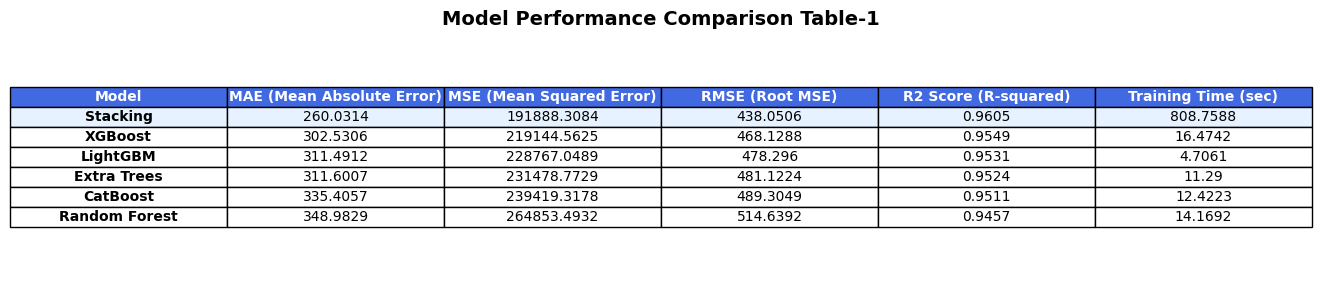

Table successfully saved as PNG at: /content/drive/MyDrive/Dataset /model_comparison_table-1.png


In [ ]:
import matplotlib.pyplot as plt

# 1. Set figure size
fig, ax = plt.subplots(figsize=(14, 3.2))
ax.axis('off')
ax.axis('tight')

# 2. Convert result dataframe to matplotlib table
table_data = results.round(4)
table = ax.table(cellText=table_data.values,
                 colLabels=table_data.columns,
                 cellLoc='center',
                 loc='center')

# 3. Configure table design and font size
table.auto_set_font_size(False)
table.set_fontsize(10)
table.scale(1.2, 1.2)

# 4. Apply styling (Headers, Best Model row highlighting, and Model name bolding)
for key, cell in table.get_celld().items():
    if key[0] == 0:  # Header row (Column names)
        cell.set_facecolor('#4169E1') # Royal Blue color
        cell.set_text_props(weight='bold', color='white')
    elif key[0] == 1:  # Best model row (First data row)
        cell.set_facecolor('#E6F2FF') # Light blue highlight for the best model
        if key[1] == 0:  # Bold the model name
            cell.set_text_props(weight='bold')
    elif key[1] == 0:  # Bold all other model names in the first column
        cell.set_text_props(weight='bold')

# 5. Place the title directly above the table with zero extra vertical gap
ax.text(0.5, 1.02, "Model Performance Comparison Table-1",
        transform=ax.transAxes,
        fontsize=14,
        weight='bold',
        ha='center',
        va='bottom')

# 6. Save the table as a high-resolution PNG file
output_img_path = '/content/drive/MyDrive/Dataset /model_comparison_table-1.png'
plt.savefig(output_img_path, bbox_inches='tight', dpi=300)
plt.show()

print(f"Table successfully saved as PNG at: {output_img_path}")

### Macro vs. Weighted Average

| Average | How it is computed | Meaning |
|---|---|---|
| **Macro** | Simple mean of the per-class scores | Every class counts **equally** |
| **Weighted** | Mean weighted by the number of samples in each class | Bigger classes count **more** |



## 14. Confusion Matrix

Rows = **actual** class, columns = **predicted** class. The diagonal shows correct predictions.

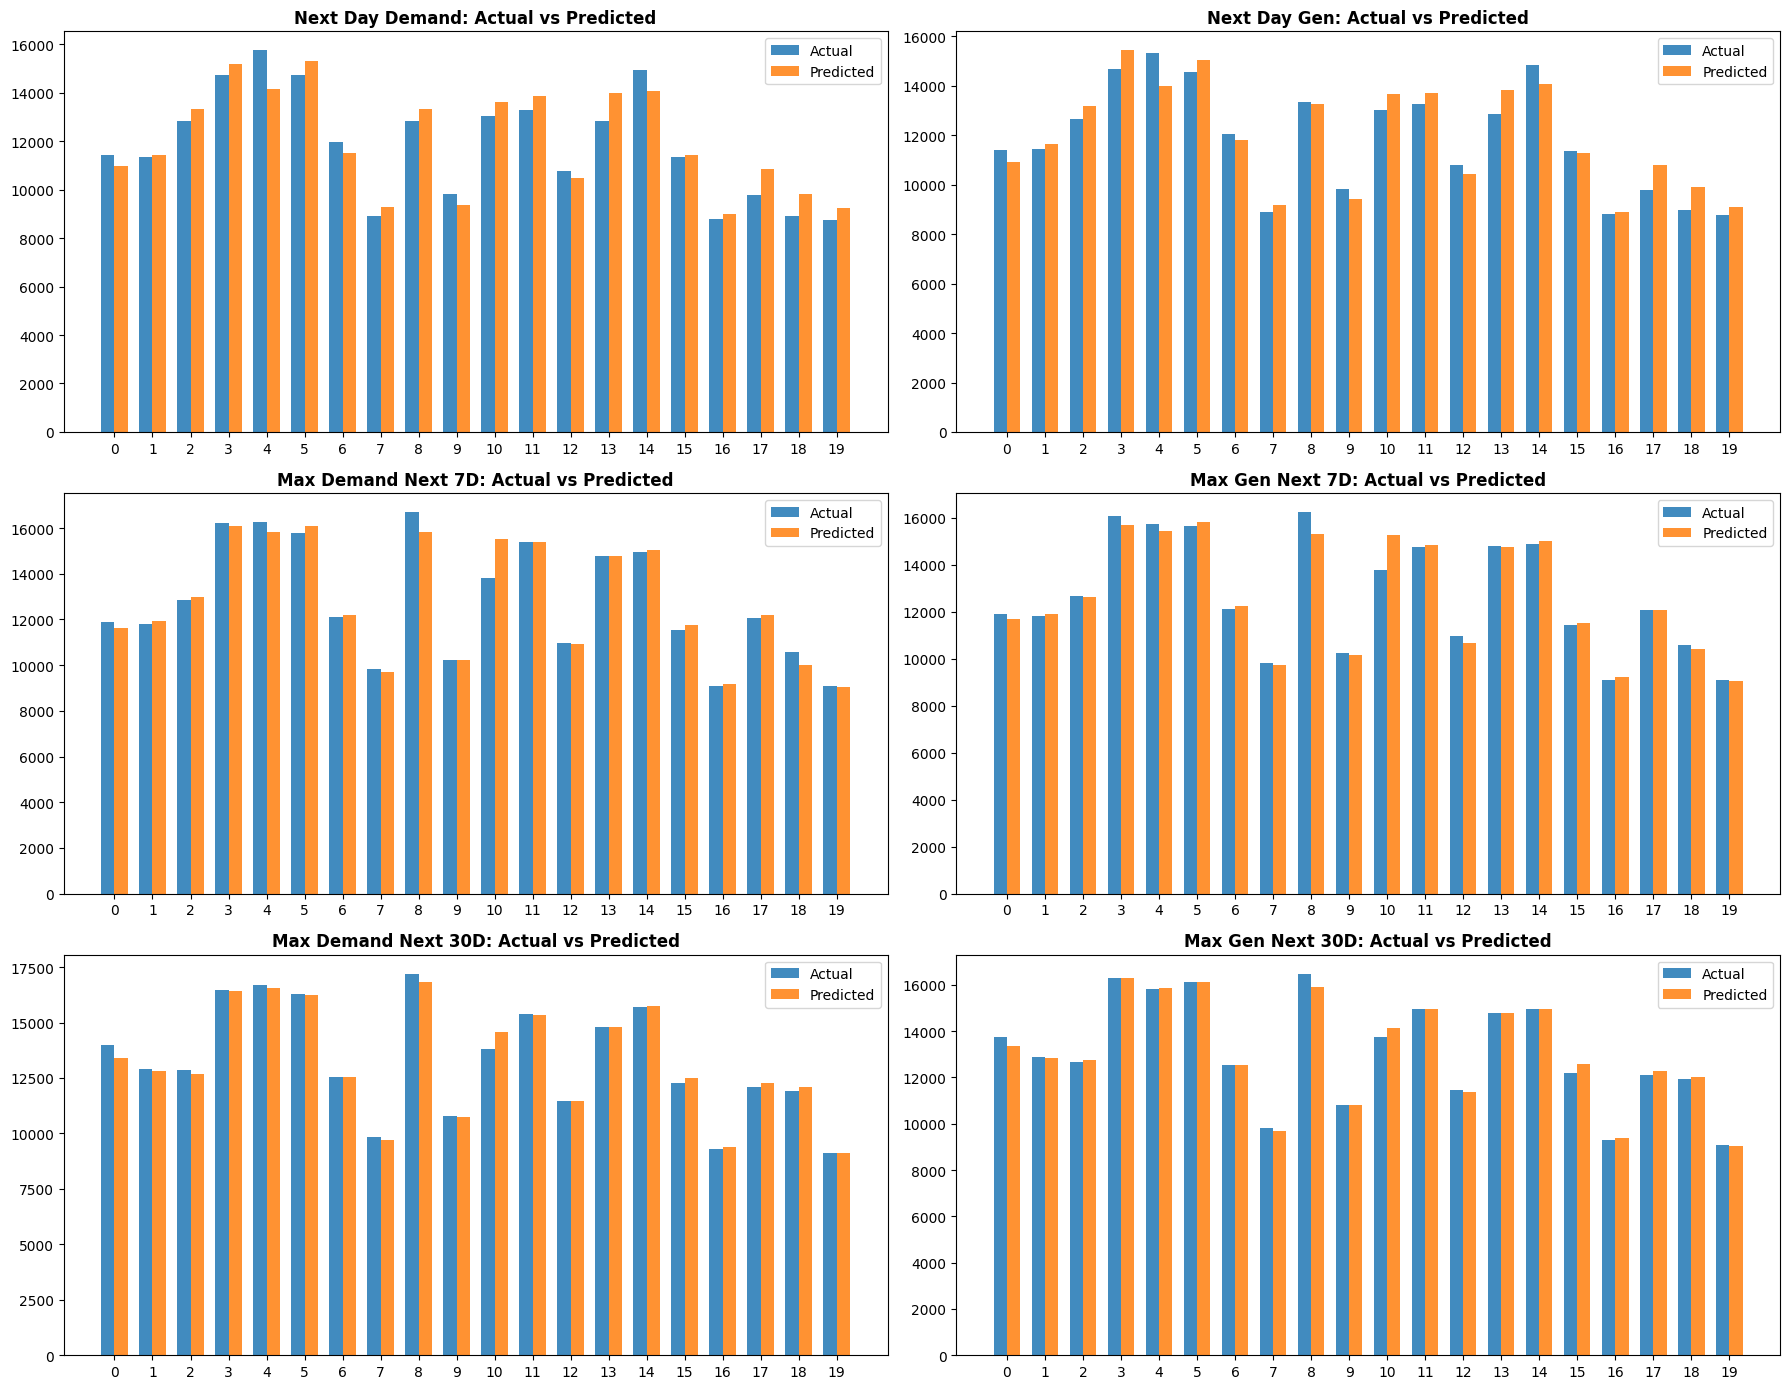

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

num_samples = 20
indices = np.arange(num_samples)
width = 0.35

target_cols = y_test.columns

preds = stack_pred[:num_samples]

fig, axes = plt.subplots(3, 2, figsize=(18, 14))
axes = axes.ravel()

for i, col_name in enumerate(target_cols):
    actual_subset = y_test[col_name].iloc[:num_samples].values


    predicted_subset = preds[:, i] if preds.ndim > 1 else preds[:num_samples]

    axes[i].bar(indices - width/2, actual_subset, width, label='Actual', color='#1f77b4', alpha=0.85)
    axes[i].bar(indices + width/2, predicted_subset, width, label='Predicted', color='#ff7f0e', alpha=0.85)

    clean_title = col_name.replace('target_', '').replace('_', ' ').title()
    axes[i].set_title(f"{clean_title}: Actual vs Predicted", fontsize=12, weight='bold')
    axes[i].set_xticks(indices)
    axes[i].legend(loc='upper right')

plt.tight_layout()
plt.show()

## 16. REC Curve

The ROC curve shows how well each model separates the classes.
A higher AUC (closer to 1.0) means better performance.

##  Hyperparameter Tuning for LightGBM and XGBoost using RandomizedSearchCV

In this step, I use `RandomizedSearchCV` to automatically find the optimal hyperparameters for our core best boosting models (LightGBM and XGBoost) to maximize regression accuracy.

In [ ]:
from sklearn.model_selection import RandomizedSearchCV
import lightgbm as lgb
import xgboost as xgb
from sklearn.multioutput import MultiOutputRegressor

print("Starting Hyperparameter Tuning for LightGBM...")

# Define parameter grid for LightGBM
lgb_param_dist = {
    'estimator__n_estimators': [100, 200, 300],
    'estimator__learning_rate': [0.01, 0.05, 0.1],
    'estimator__max_depth': [4, 6, 8],
    'estimator__num_leaves': [15, 31, 63],
    'estimator__subsample': [0.7, 0.8, 1.0]
}

# MultiOutput Wrapper on base model for search
base_lgb_search = MultiOutputRegressor(lgb.LGBMRegressor(random_state=RANDOM_STATE, verbose=-1, n_jobs=-1))

lgb_random_search = RandomizedSearchCV(
    estimator=base_lgb_search,
    param_distributions=lgb_param_dist,
    n_iter=20,
    scoring='r2',
    cv=5,
    random_state=RANDOM_STATE,
    n_jobs=-1
)

# Fit LightGBM Search
lgb_random_search.fit(X_train_scaled, y_train)
print("Best LightGBM Parameters found:", lgb_random_search.best_params_)

print("\nStarting Hyperparameter Tuning for XGBoost...")



Starting Hyperparameter Tuning for LightGBM...
Best LightGBM Parameters found: {'estimator__subsample': 1.0, 'estimator__num_leaves': 15, 'estimator__n_estimators': 300, 'estimator__max_depth': 6, 'estimator__learning_rate': 0.1}

Starting Hyperparameter Tuning for XGBoost...
Best XGBoost Parameters found: {'estimator__subsample': 0.8, 'estimator__n_estimators': 300, 'estimator__max_depth': 6, 'estimator__learning_rate': 0.05, 'estimator__colsample_bytree': 0.8}


In [ ]:
# Define parameter grid for XGBoost
xgb_param_dist = {
    'estimator__n_estimators': [100, 200, 300],
    'estimator__learning_rate': [0.01, 0.05, 0.1],
    'estimator__max_depth': [4, 6, 8],
    'estimator__subsample': [0.7, 0.8, 1.0],
    'estimator__colsample_bytree': [0.7, 0.8, 1.0]
}

base_xgb_search = MultiOutputRegressor(xgb.XGBRegressor(random_state=RANDOM_STATE, n_jobs=-1))

xgb_random_search = RandomizedSearchCV(
    estimator=base_xgb_search,
    param_distributions=xgb_param_dist,
    n_iter=20,
    scoring='r2',
    cv=5,
    random_state=RANDOM_STATE,
    n_jobs=-1
)

# Fit XGBoost Search
xgb_random_search.fit(X_train_scaled, y_train)
print("Best XGBoost Parameters found:", xgb_random_search.best_params_)

Best XGBoost Parameters found: {'estimator__subsample': 0.8, 'estimator__n_estimators': 300, 'estimator__max_depth': 6, 'estimator__learning_rate': 0.05, 'estimator__colsample_bytree': 0.8}


## Block 2: Evaluating the Tuned Models & Plotting Improved REC Curves

In this step, I extract the best estimators from our randomized searches, predict on the test set, and evaluate if the hyperparameter optimization successfully boosted our $R^2$ score and Regression Error Characteristic (REC) area.

In [ ]:
from sklearn.metrics import mean_absolute_error, r2_score
import numpy as np
import matplotlib.pyplot as plt

# 1. Extract the best tuned models from our search
best_tuned_lgb = lgb_random_search.best_estimator_
best_tuned_xgb = xgb_random_search.best_estimator_

# 2. Predict on test set using the optimized models
tuned_lgb_pred = best_tuned_lgb.predict(X_test_scaled)
tuned_xgb_pred = best_tuned_xgb.predict(X_test_scaled)

# 3. Calculate scores for comparison
old_lgb_r2 = r2_score(y_test, lgb_pred, multioutput='uniform_average')
new_lgb_r2 = r2_score(y_test, tuned_lgb_pred, multioutput='uniform_average')

old_xgb_r2 = r2_score(y_test, xgb_pred, multioutput='uniform_average')
new_xgb_r2 = r2_score(y_test, tuned_xgb_pred, multioutput='uniform_average')

print(f"LightGBM R2 Score: Previous = {old_lgb_r2:.4f} | Tuned = {new_lgb_r2:.4f}")
print(f"XGBoost R2 Score:  Previous = {old_xgb_r2:.4f} | Tuned = {new_xgb_r2:.4f}")



LightGBM R2 Score: Previous = 0.9531 | Tuned = 0.9536
XGBoost R2 Score:  Previous = 0.9549 | Tuned = 0.9546


## Hyperparameter Tuning for Random Forest, Extra Trees, and CatBoost




## Stacking Ensemble after Passing Tuned Models

In [ ]:
from sklearn.ensemble import StackingRegressor
from sklearn.linear_model import LinearRegression
from sklearn.multioutput import MultiOutputRegressor

print("--- Training Stacking Regressor ---")


base_stack = StackingRegressor(
    estimators=[
        ("rf", rf_random_search.best_estimator_),              # Single/Multi natively supported)
        ("et", et_random_search.best_estimator_),              #Single/Multi natively supported)
        ("xgb", xgb_random_search.best_estimator_.estimator),  # single Regressor extarcting from MultiOutputRegressor
        ("lgb", lgb_random_search.best_estimator_.estimator),
        ("cat", cat_random_search.best_estimator_.estimator)
    ],
    final_estimator=LinearRegression(),
    cv=5,
    n_jobs=-1
)

stack_model = MultiOutputRegressor(base_stack)


stack_model.fit(X_train_scaled, y_train)
stack_pred = stack_model.predict(X_test_scaled)

print("Stacking Model training and prediction completed successfully!")

--- Training Stacking Regressor ---
Stacking Model training and prediction completed successfully!


## Model Comparison Table after Tunning

## Save Tuned Stacking Model and Dataset (X_train_scaled, X_test_scaled, y_train, y_test)

In [ ]:
import joblib
import os

# check Google Drive mounting path
save_path = '/content/drive/MyDrive/Dataset /'
os.makedirs(save_path, exist_ok=True)

# 1. Stacking Model save
joblib.dump(stack_model, os.path.join(save_path, 'stack_model.pkl'))

# 2. Save Required Datasets (X_train_scaled, X_test_scaled, y_train, y_test)
joblib.dump(X_train_scaled, os.path.join(save_path, 'X_train_scaled.pkl'))
joblib.dump(X_test_scaled, os.path.join(save_path, 'X_test_scaled.pkl'))
joblib.dump(y_train, os.path.join(save_path, 'y_train.pkl'))
joblib.dump(y_test, os.path.join(save_path, 'y_test.pkl'))

print("Stack model and required datasets successfully saved !")

Stack model and required datasets successfully saved !


# Load Models and Dataset for Next-time use
Just Run previous code before any model training and then run from here next time

In [ ]:
import joblib
import os

load_path = '/content/drive/MyDrive/Dataset /'

# 1. Saved model ebong dataset gulo load kora
loaded_stack_model = joblib.load(os.path.join(load_path, 'stack_model.pkl'))
X_train_scaled = joblib.load(os.path.join(load_path, 'X_train_scaled.pkl'))
X_test_scaled = joblib.load(os.path.join(load_path, 'X_test_scaled.pkl'))
y_train = joblib.load(os.path.join(load_path, 'y_train.pkl'))
y_test = joblib.load(os.path.join(load_path, 'y_test.pkl'))

print("successfully loaded tuned Stacked model and required datasets!")


FileNotFoundError: [Errno 2] No such file or directory: '/content/drive/MyDrive/Dataset /stack_model.pkl'

# Output: FInal Tuned Stacking (Hybrid Model) and evaluate with overall and targetwise metrics

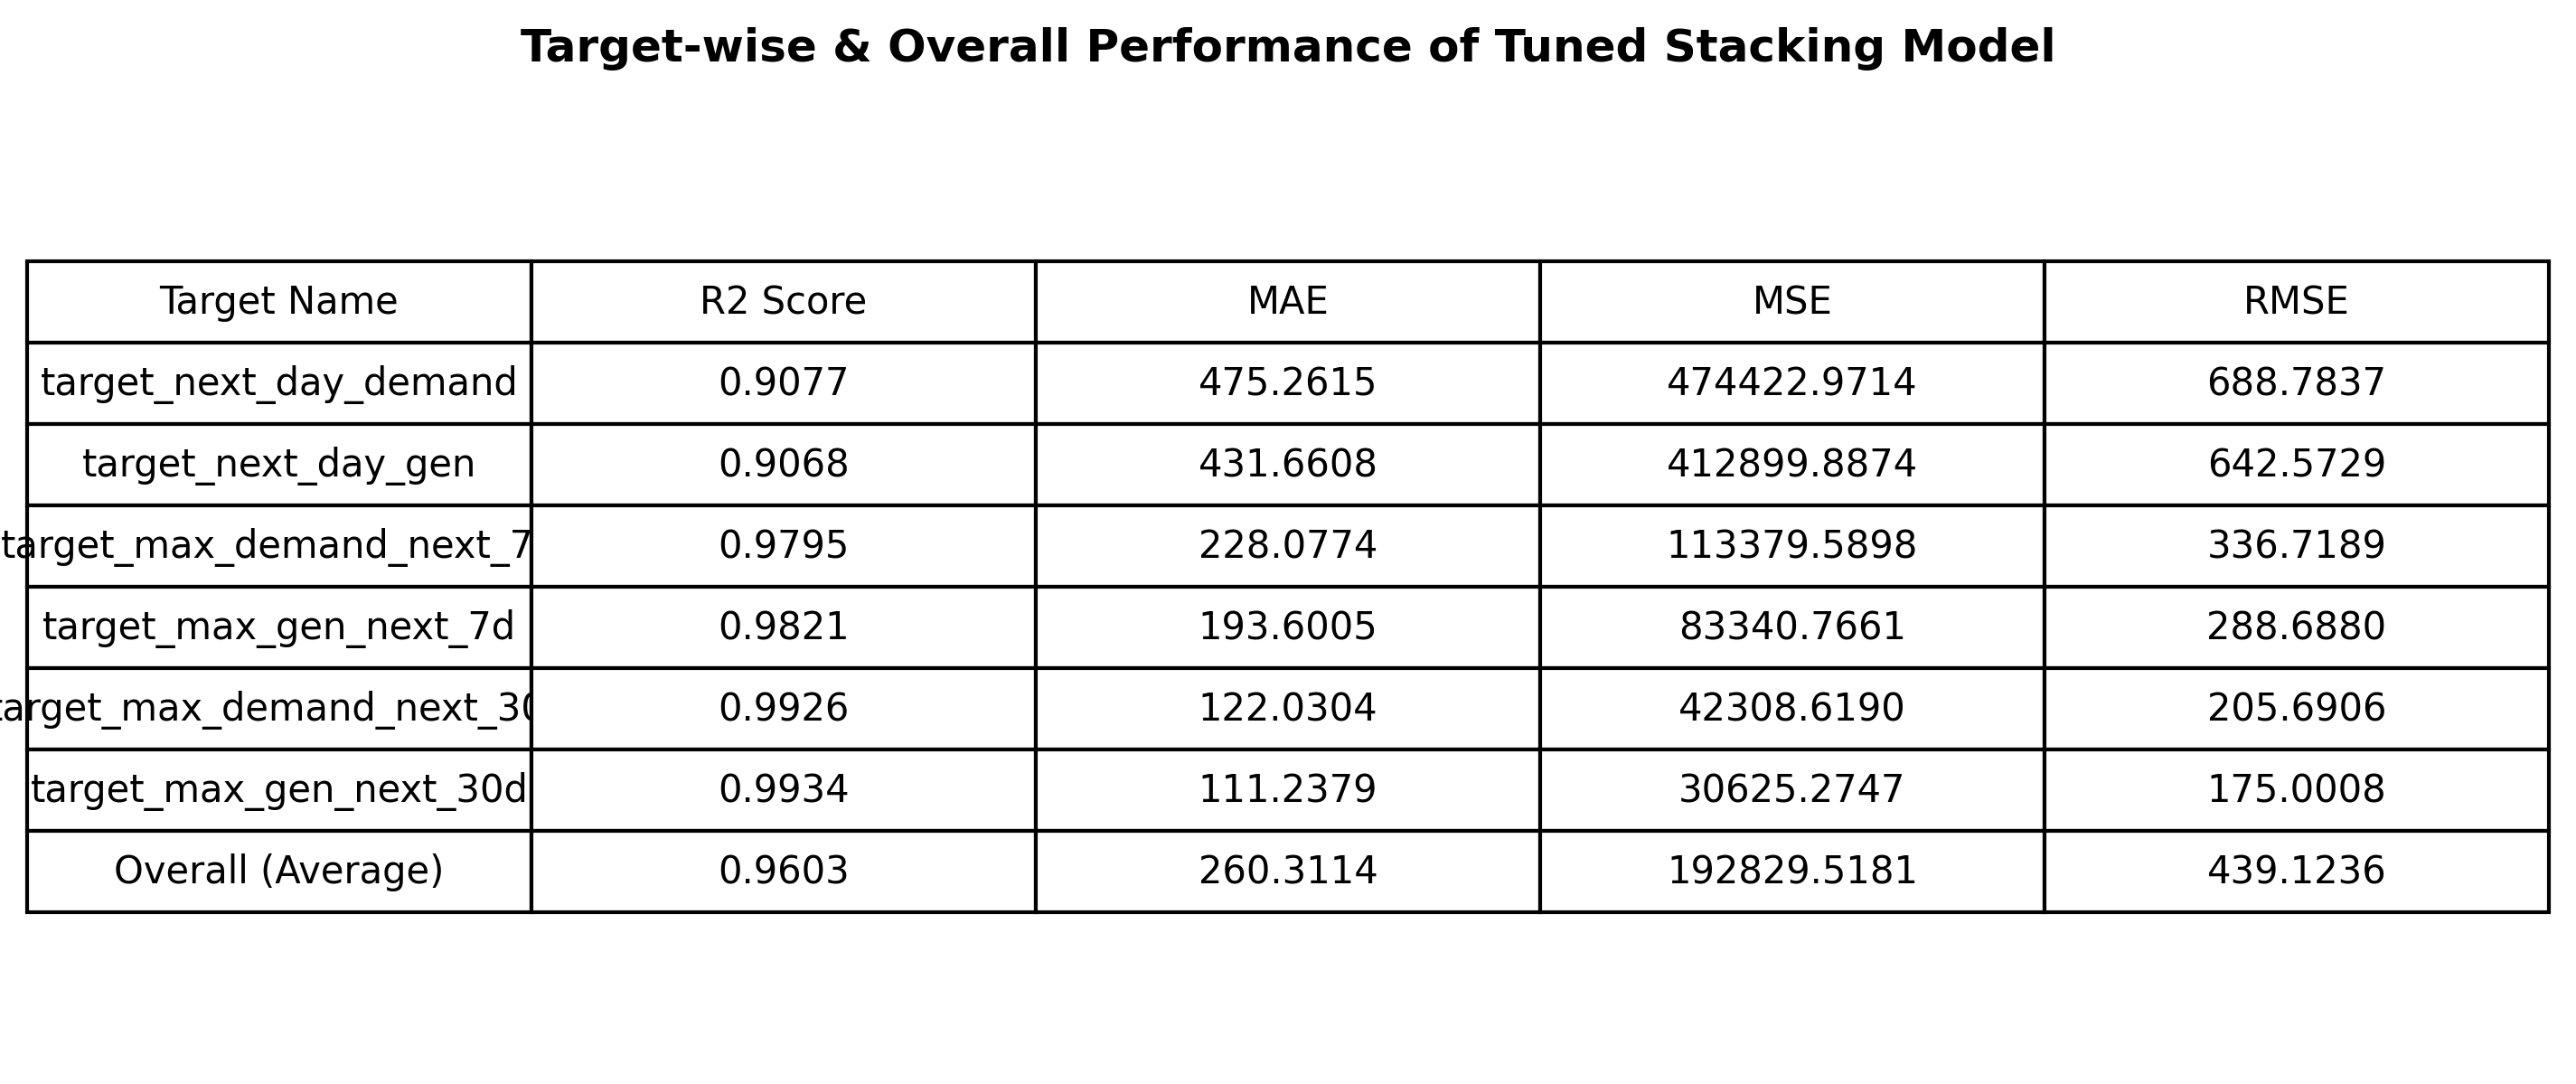

Table successfully saved at: /content/drive/MyDrive/Dataset /stacking_target_wise_performance.png


In [ ]:
# Output: FInal Tuned Stacking (Hybrid Model) and evaluate with overall and targetwise metrics

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import os
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

# Define actual target names
TARGET = [
    'target_next_day_demand',
    'target_next_day_gen',
    'target_max_demand_next_7d',
    'target_max_gen_next_7d',
    'target_max_demand_next_30d',
    'target_max_gen_next_30d'
]

# Predict using the loaded stacking model
stack_pred = loaded_stack_model.predict(X_test_scaled)

# Calculate Overall Scores
overall_r2 = r2_score(y_test, stack_pred, multioutput='uniform_average')
overall_mae = mean_absolute_error(y_test, stack_pred)
overall_mse = mean_squared_error(y_test, stack_pred)
overall_rmse = np.sqrt(overall_mse)

# Calculate Target-wise Scores
r2_per_target = r2_score(y_test, stack_pred, multioutput='raw_values')
mae_per_target = mean_absolute_error(y_test, stack_pred, multioutput='raw_values')
mse_per_target = mean_squared_error(y_test, stack_pred, multioutput='raw_values')
rmse_per_target = np.sqrt(mse_per_target)

# Prepare DataFrame rows
table_rows = []
for idx, name in enumerate(TARGET):
    table_rows.append({
        "Target Name": name,
        "R2 Score": f"{r2_per_target[idx]:.4f}",
        "MAE": f"{mae_per_target[idx]:.4f}",
        "MSE": f"{mse_per_target[idx]:.4f}",
        "RMSE": f"{rmse_per_target[idx]:.4f}"
    })

# Add Overall row
table_rows.append({
    "Target Name": "Overall (Average)",
    "R2 Score": f"{overall_r2:.4f}",
    "MAE": f"{overall_mae:.4f}",
    "MSE": f"{overall_mse:.4f}",
    "RMSE": f"{overall_rmse:.4f}"
})

df_metrics = pd.DataFrame(table_rows)

# Create a clean, simple table plot
plt.figure(figsize=(10, 4.5), dpi=300)
ax = plt.subplot(111, frame_on=False)
ax.xaxis.set_visible(False)
ax.yaxis.set_visible(False)

table = plt.table(
    cellText=df_metrics.values.tolist(),
    colLabels=list(df_metrics.columns),
    loc='center',
    cellLoc='center'
)

table.auto_set_font_size(False)
table.set_fontsize(10)
table.scale(1.2, 1.8)

plt.title("Target-wise & Overall Performance of Tuned Stacking Model", fontsize=12, weight='bold', pad=15)

# Save as PNG in Google Drive
save_path = '/content/drive/MyDrive/Dataset '
os.makedirs(save_path, exist_ok=True)
output_img_path = os.path.join(save_path, 'stacking_target_wise_performance.png')

plt.savefig(output_img_path, bbox_inches='tight', dpi=300)
plt.show()

print(f"Table successfully saved at: {output_img_path}")

## Hyperparameter tunned models evaaluation metrics comparision table

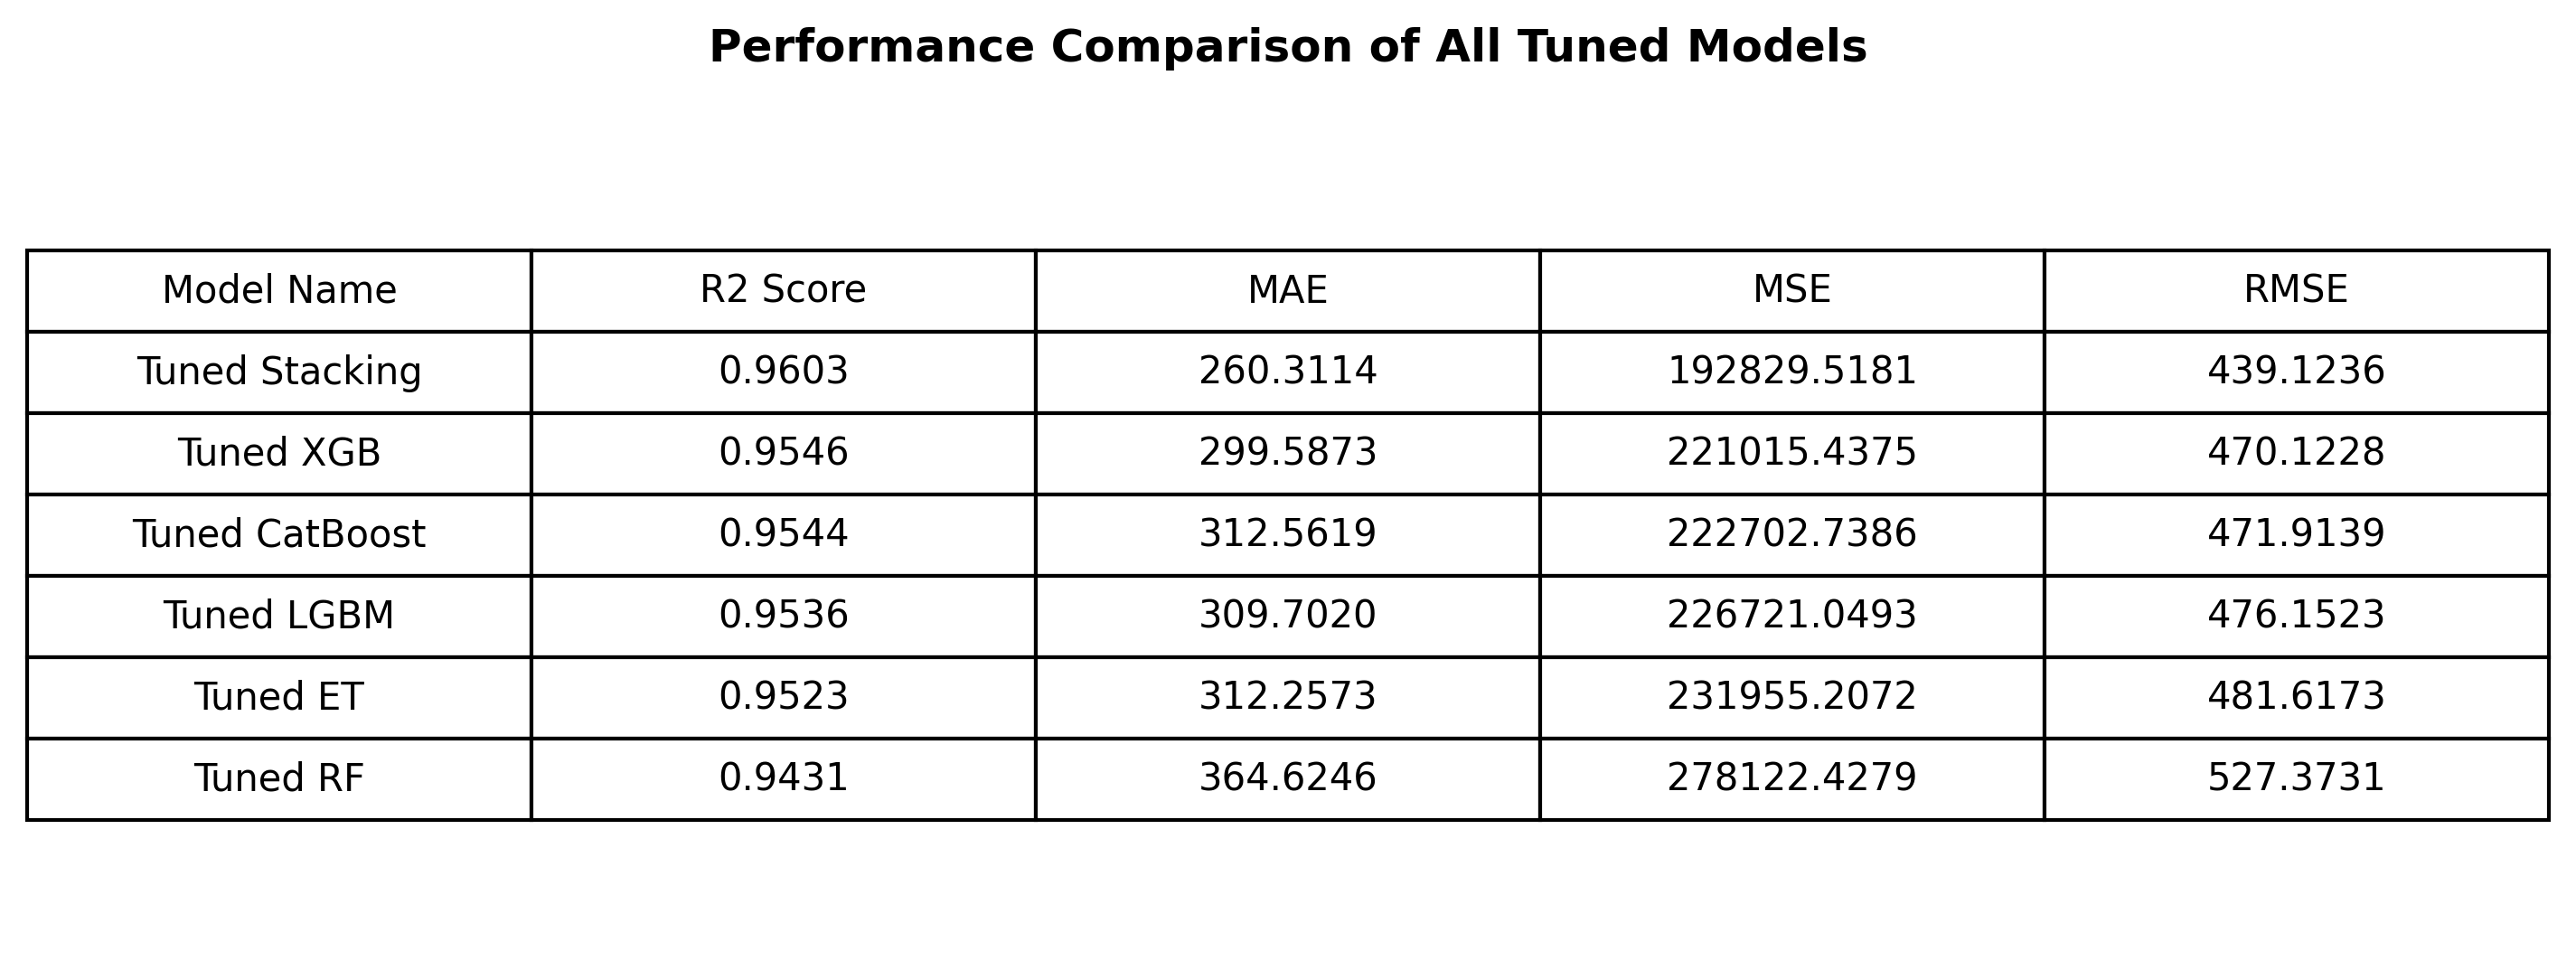

Models comparison table successfully saved at: /content/drive/MyDrive/Dataset /all_tuned_models_performance.png


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import os
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

# Define target names
TARGET = [
    'target_next_day_demand',
    'target_next_day_gen',
    'target_max_demand_next_7d',
    'target_max_gen_next_7d',
    'target_max_demand_next_30d',
    'target_max_gen_next_30d'
]

# Generate predictions for all tuned models and stacking model
preds = {
    "Tuned RF": rf_random_search.best_estimator_.predict(X_test_scaled),
    "Tuned ET": et_random_search.best_estimator_.predict(X_test_scaled),
    "Tuned XGB": xgb_random_search.best_estimator_.predict(X_test_scaled),
    "Tuned LGBM": lgb_random_search.best_estimator_.predict(X_test_scaled),
    "Tuned CatBoost": cat_random_search.best_estimator_.predict(X_test_scaled),
    "Tuned Stacking": loaded_stack_model.predict(X_test_scaled)
}

# Calculate R2, MAE, MSE, RMSE for each model
model_scores = []
for name, pred in preds.items():
    r2 = r2_score(y_test, pred, multioutput='uniform_average')
    mae = mean_absolute_error(y_test, pred)
    mse = mean_squared_error(y_test, pred)
    rmse = np.sqrt(mse)

    model_scores.append({
        "Model Name": name,
        "R2 Score": f"{r2:.4f}",
        "MAE": f"{mae:.4f}",
        "MSE": f"{mse:.4f}",
        "RMSE": f"{rmse:.4f}"
    })

df_models = pd.DataFrame(model_scores).sort_values(by="R2 Score", ascending=False).reset_index(drop=True)

# Create a clean, simple table plot
plt.figure(figsize=(10, 4), dpi=300)
ax = plt.subplot(111, frame_on=False)
ax.xaxis.set_visible(False)
ax.yaxis.set_visible(False)

table = plt.table(
    cellText=df_models.values.tolist(),
    colLabels=list(df_models.columns),
    loc='center',
    cellLoc='center'
)

table.auto_set_font_size(False)
table.set_fontsize(10)
table.scale(1.2, 1.8)

plt.title("Performance Comparison of All Tuned Models", fontsize=12, weight='bold', pad=15)

# Save as PNG in Google Drive
save_path = '/content/drive/MyDrive/Dataset '
os.makedirs(save_path, exist_ok=True)
output_img_path = os.path.join(save_path, 'all_tuned_models_performance.png')

plt.savefig(output_img_path, bbox_inches='tight', dpi=300)
plt.show()

print(f"Models comparison table successfully saved at: {output_img_path}")

## REC Curve

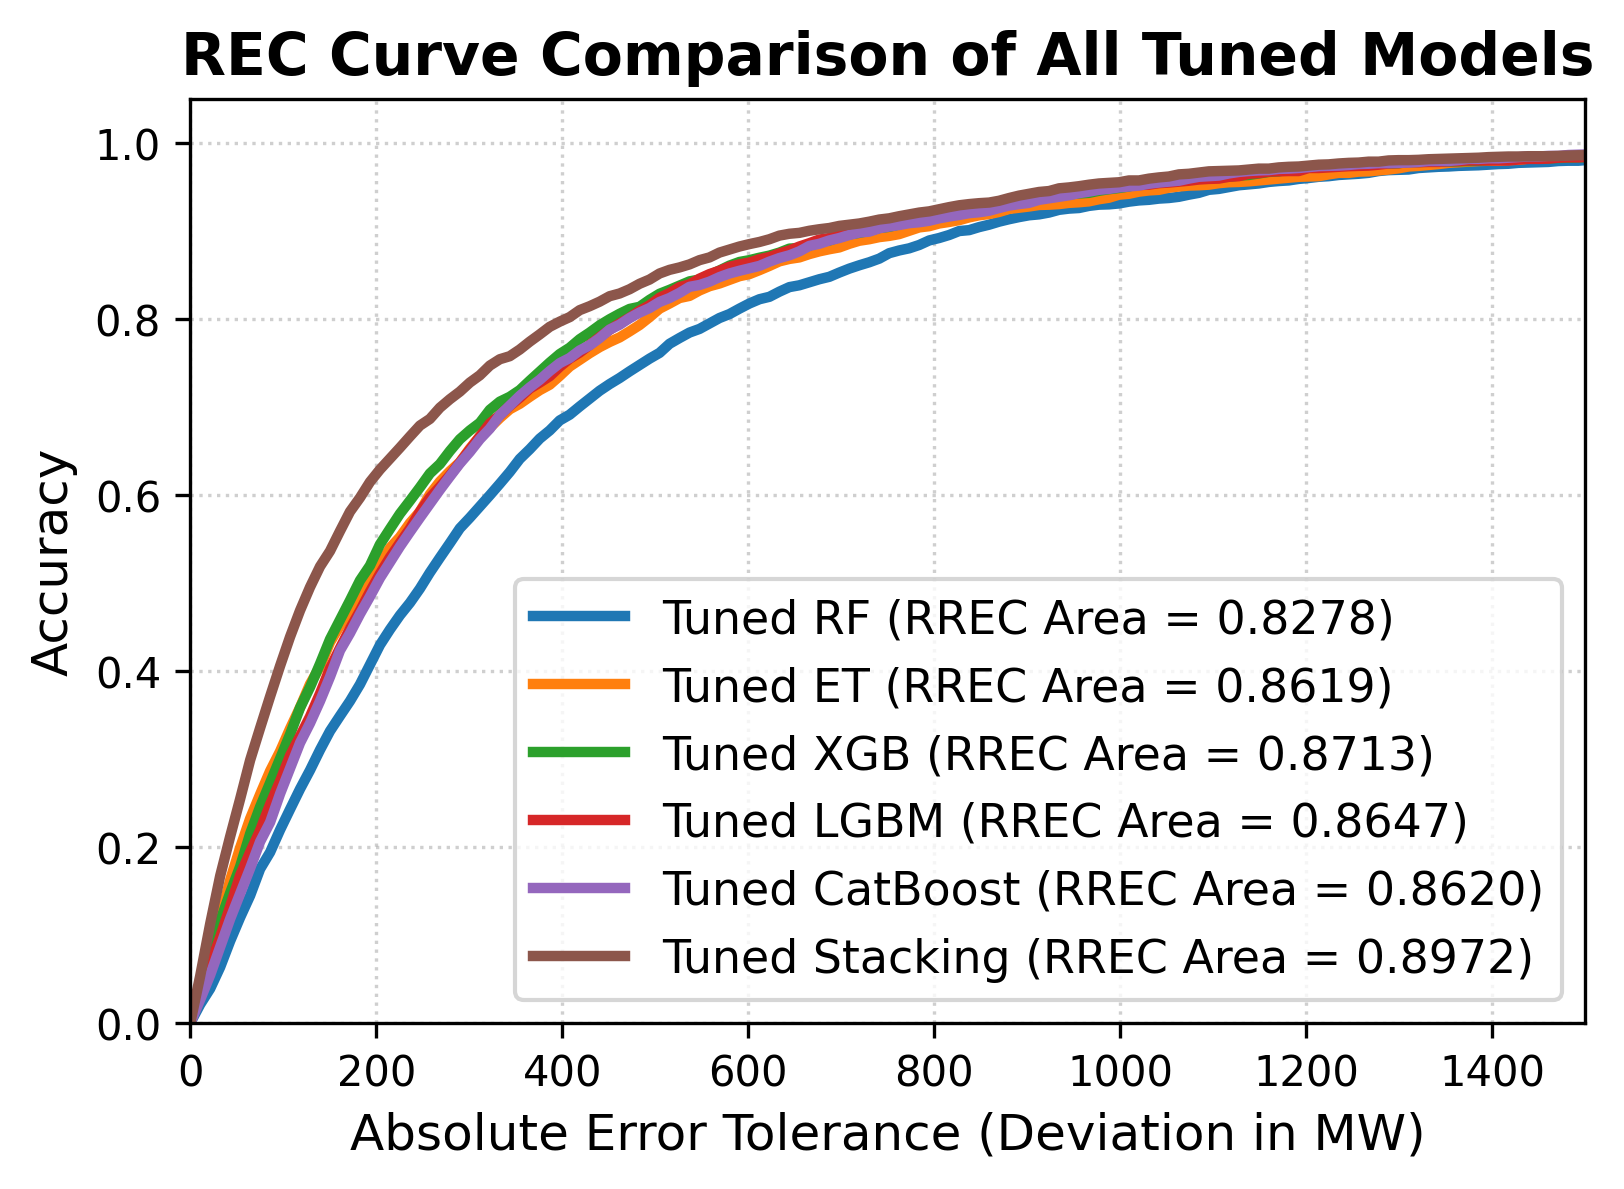

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import os

# Calculate  REC Curves for final comparison
plt.figure(figsize=(6, 4), dpi=300)
tolerances = np.linspace(0, 1600, 150)

# Make sure tuned_models dictionary is ready (RF, ET, XGB, LGBM, CatBoost, Stacking)
tuned_models = {
    "Tuned RF": rf_random_search.best_estimator_.predict(X_test_scaled),
    "Tuned ET": et_random_search.best_estimator_.predict(X_test_scaled),
    "Tuned XGB": xgb_random_search.best_estimator_.predict(X_test_scaled),
    "Tuned LGBM": lgb_random_search.best_estimator_.predict(X_test_scaled),
    "Tuned CatBoost": cat_random_search.best_estimator_.predict(X_test_scaled),
    "Tuned Stacking": loaded_stack_model.predict(X_test_scaled)
}

for name, pred in tuned_models.items():
    y_true_val = y_test.values if hasattr(y_test, "values") else y_test
    rec_scores = calculate_rec_curve(y_true_val, pred, tolerances)
    auc_rec = np.trapz(rec_scores, tolerances) / 1500.0
    plt.plot(tolerances, rec_scores, label=f"{name} (RREC Area = {auc_rec:.4f})", lw=2.5)

plt.title("REC Curve Comparison of All Tuned Models", fontsize=14, weight='bold')
plt.xlabel("Absolute Error Tolerance (Deviation in MW)", fontsize=12)
plt.ylabel("Accuracy", fontsize=12)
plt.xlim(0, 1500)
plt.ylim(0, 1.05)
plt.grid(True, linestyle=':', alpha=0.6)
plt.legend(loc='lower right', fontsize=11)

# Save to Google Drive
save_path = '/content/drive/MyDrive/Dataset '
os.makedirs(save_path, exist_ok=True)
plt.savefig(os.path.join(save_path, 'rec_curve_comparison.png'), bbox_inches='tight', dpi=300)
plt.show()

## Model prediction Visualization

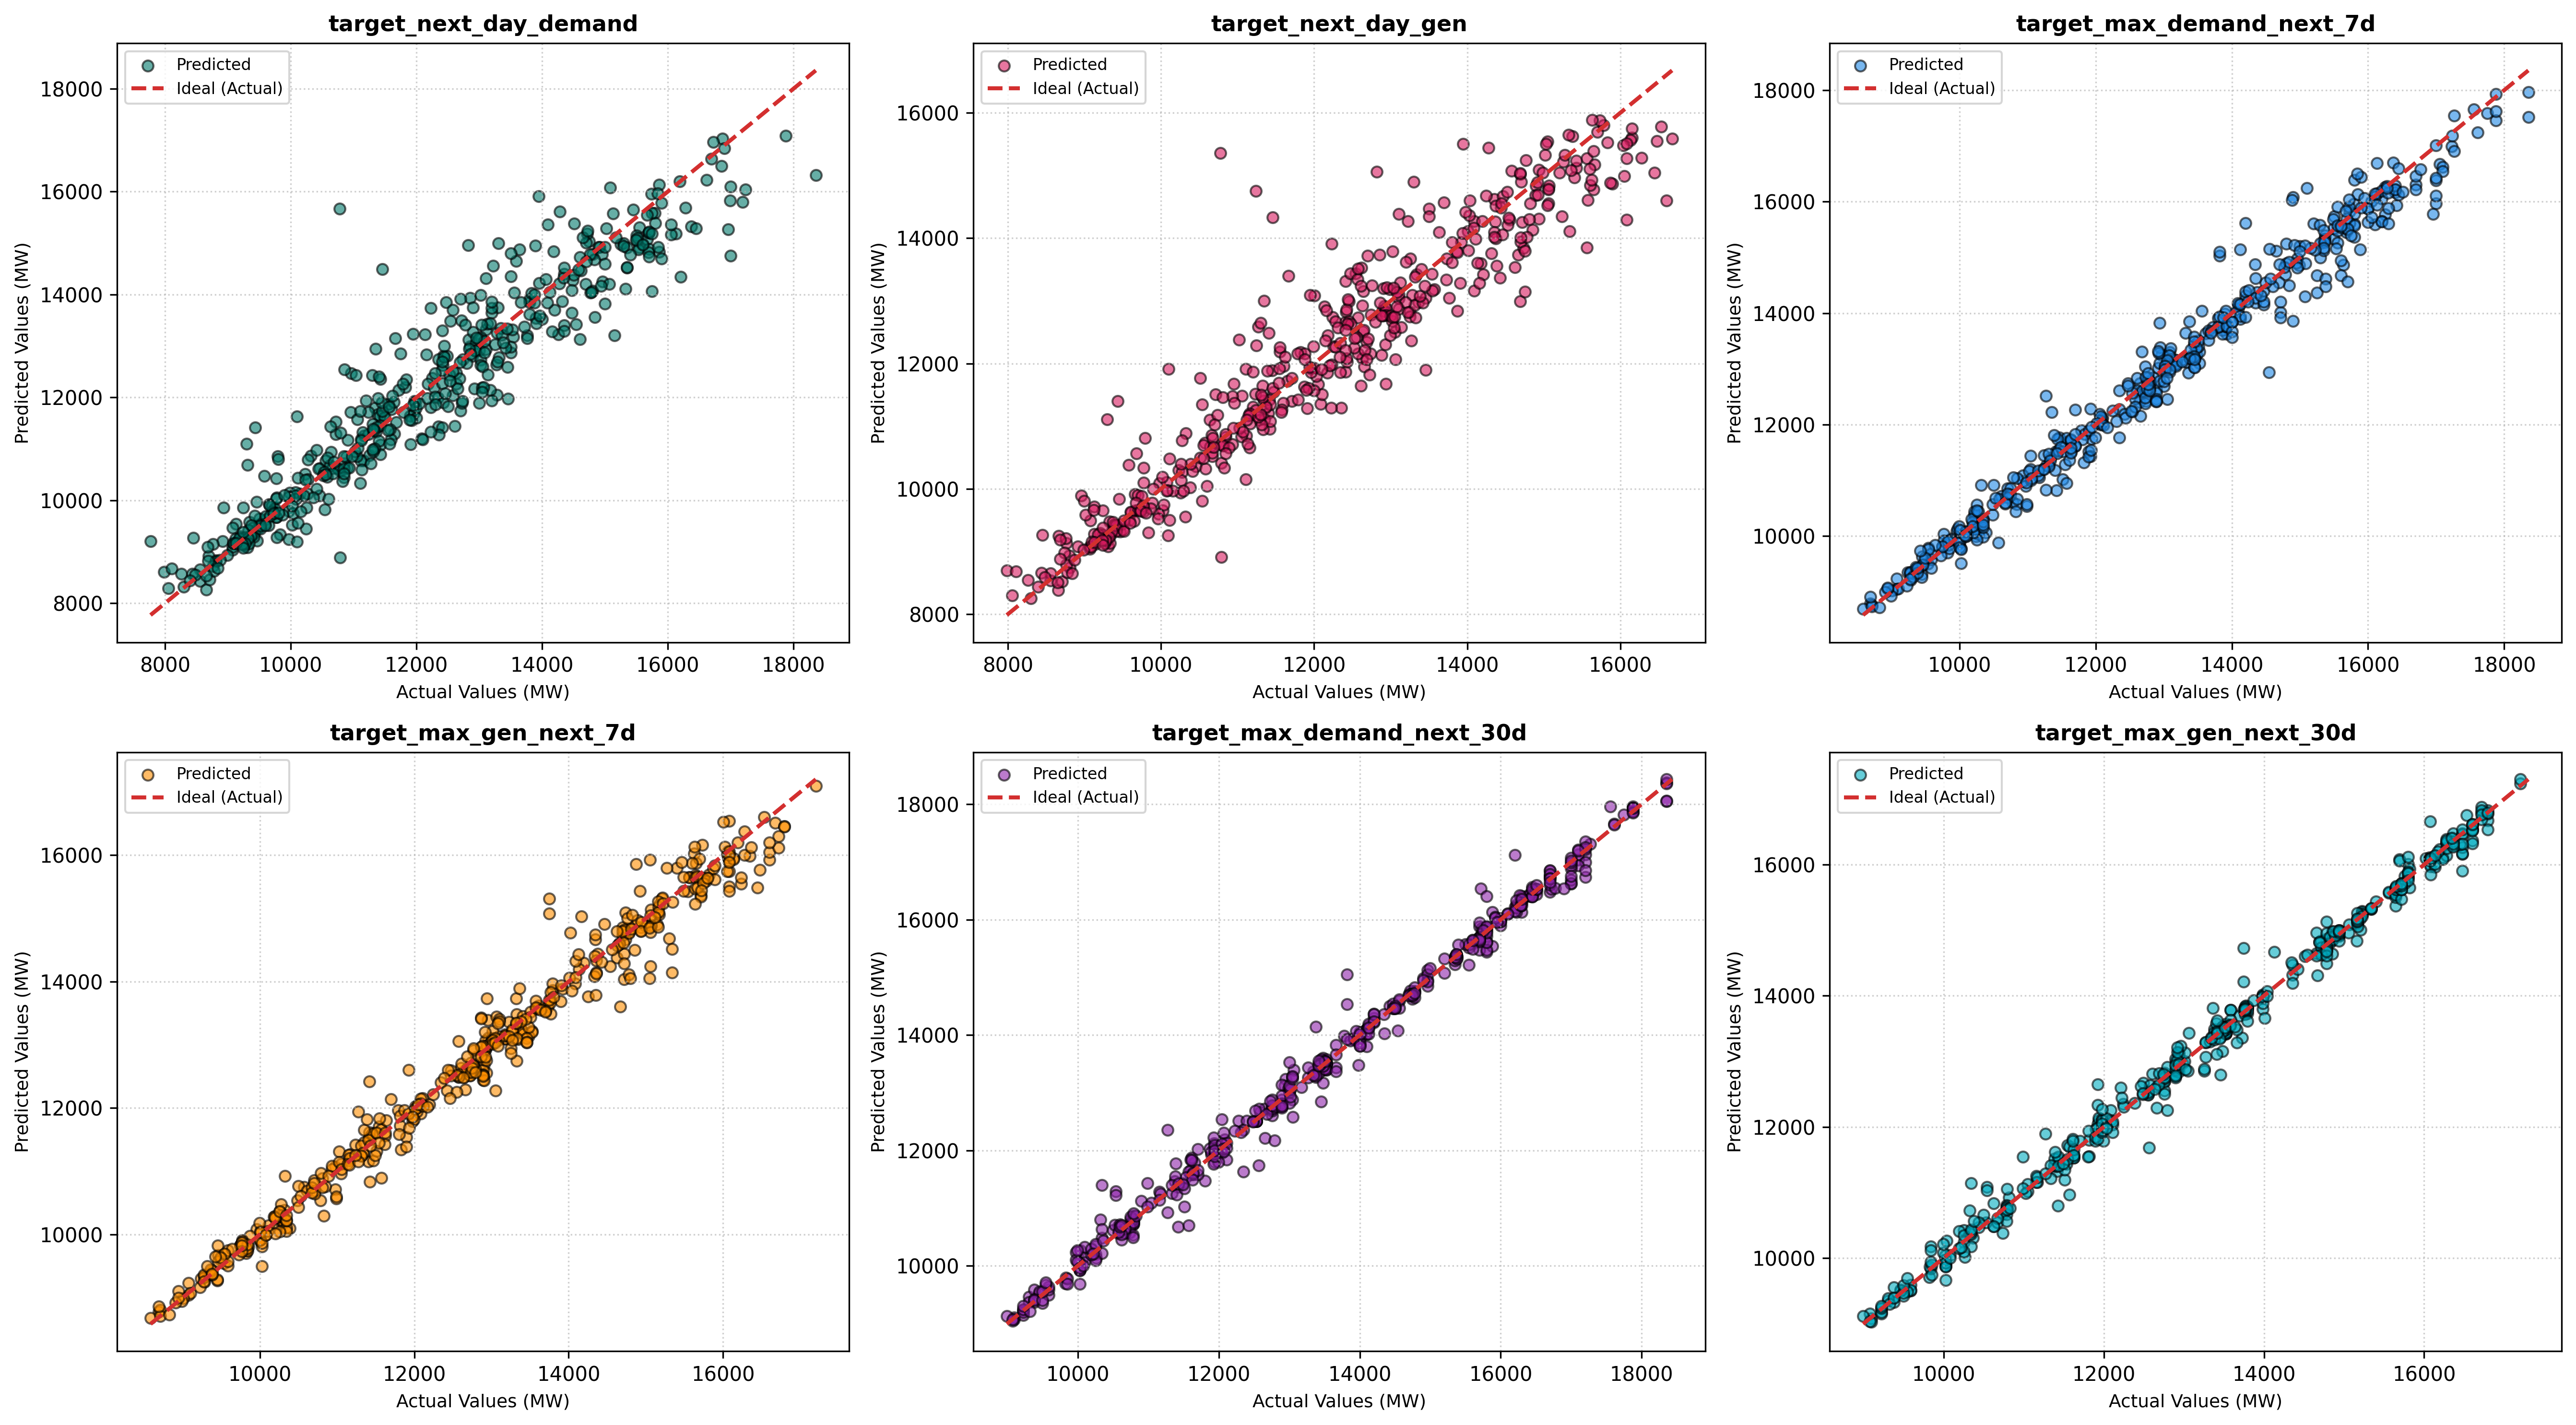

Target-wise Parity plots successfully saved at: /content/drive/MyDrive/Dataset /stacking_target_wise_parity_plots.png


In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import os

# 1. Define the 6 target names
TARGET = [
    'target_next_day_demand',
    'target_next_day_gen',
    'target_max_demand_next_7d',
    'target_max_gen_next_7d',
    'target_max_demand_next_30d',
    'target_max_gen_next_30d'
]

# Predict using the loaded stacking model
stack_pred = loaded_stack_model.predict(X_test_scaled)
y_true_val = y_test.values if hasattr(y_test, "values") else y_test

# 2. Plotting Parity Plot for each of the 6 targets with distinct colors
fig, axes = plt.subplots(2, 3, figsize=(18, 10), dpi=300)
axes = axes.flatten()

# Distinct colors for each target's predicted points
colors = ['#00796B', '#D81B60', '#1E88E5', '#FF8F00', '#8E24AA', '#00ACC1']

for i, target_name in enumerate(TARGET):
    ax = axes[i]
    y_true_col = y_true_val[:, i]
    y_pred_col = stack_pred[:, i]

    # Scatter plot for Predicted points (Unique color per target)
    ax.scatter(y_true_col, y_pred_col, alpha=0.6, color=colors[i], edgecolors='k', s=30, label='Predicted')

    # Ideal fit reference line (Actual values alignment)
    min_val = min(y_true_col.min(), y_pred_col.min())
    max_val = max(y_true_col.max(), y_pred_col.max())
    ax.plot([min_val, max_val], [min_val, max_val], color='#D32F2F', lw=2, linestyle='--', label='Ideal (Actual)')

    ax.set_title(f"{target_name}", fontsize=11, weight='bold')
    ax.set_xlabel("Actual Values (MW)", fontsize=9)
    ax.set_ylabel("Predicted Values (MW)", fontsize=9)
    ax.grid(True, linestyle=':', alpha=0.6)
    ax.legend(loc='upper left', fontsize=8)

plt.tight_layout()

# 3. Save as PNG in Google Drive
save_path = '/content/drive/MyDrive/Dataset '
os.makedirs(save_path, exist_ok=True)
output_img_path = os.path.join(save_path, 'stacking_target_wise_parity_plots.png')

plt.savefig(output_img_path, bbox_inches='tight', dpi=300)
plt.show()

print(f"Target-wise Parity plots successfully saved at: {output_img_path}")

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

num_samples = 20
indices = np.arange(num_samples)
width = 0.35

target_cols = y_test.columns

preds = stack_pred[:num_samples]

fig, axes = plt.subplots(3, 2, figsize=(18, 14))
axes = axes.ravel()

for i, col_name in enumerate(target_cols):
    actual_subset = y_test[col_name].iloc[:num_samples].values


    predicted_subset = preds[:, i] if preds.ndim > 1 else preds[:num_samples]

    axes[i].bar(indices - width/2, actual_subset, width, label='Actual', color='#1f77b4', alpha=0.85)
    axes[i].bar(indices + width/2, predicted_subset, width, label='Predicted', color='#ff7f0e', alpha=0.85)

    clean_title = col_name.replace('target_', '').replace('_', ' ').title()
    axes[i].set_title(f"{clean_title}: Actual vs Predicted", fontsize=12, weight='bold')
    axes[i].set_xticks(indices)
    axes[i].legend(loc='upper right')

plt.tight_layout()
plt.show()

NameError: name 'y_test' is not defined

## Smaple Dashboard for Forecasting

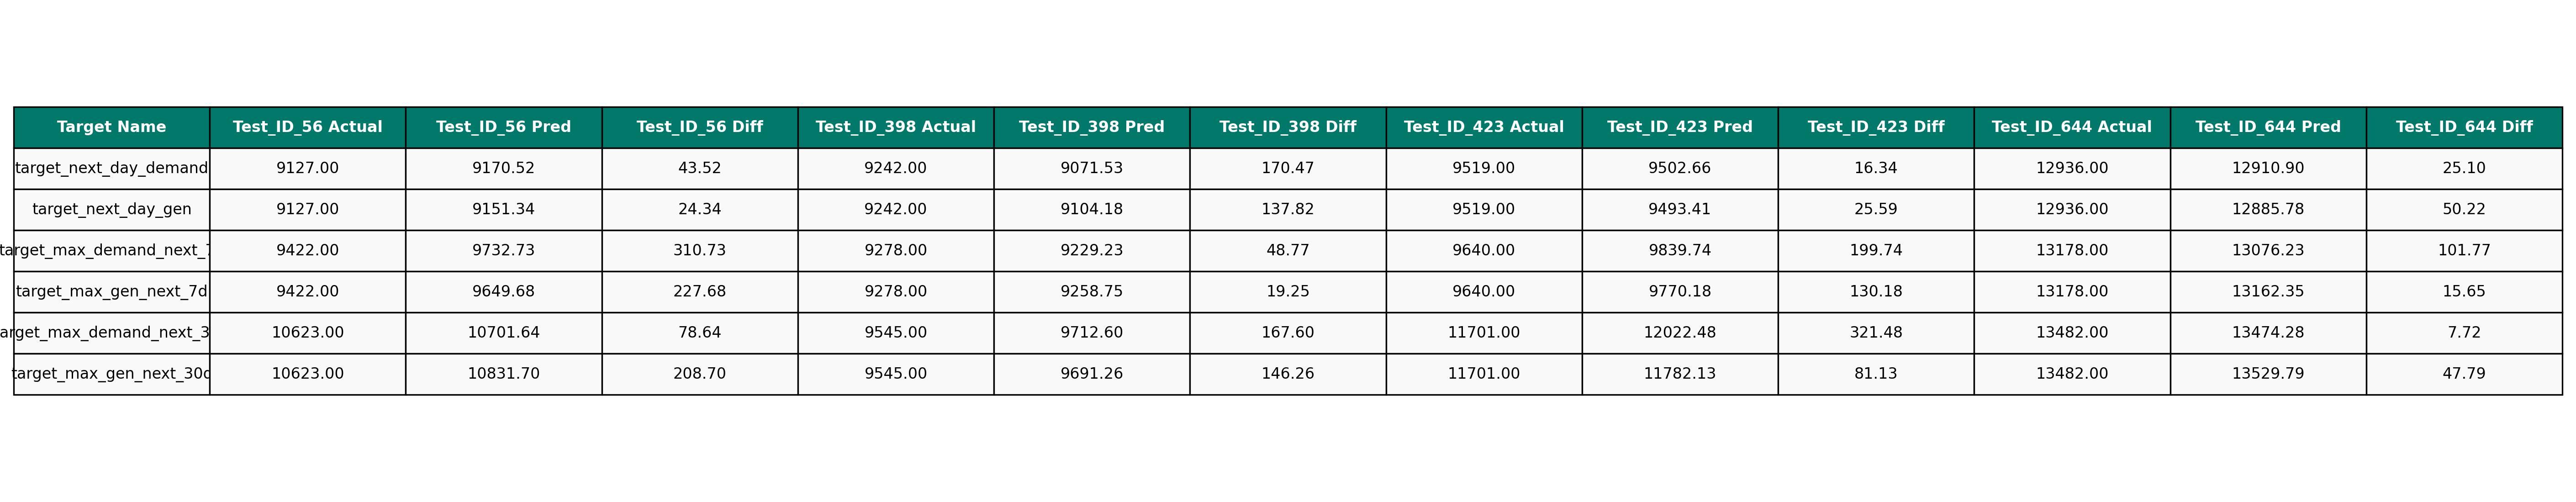

Saved successfully: /content/drive/MyDrive/Dataset /stacking_target_wise_result_table.png


In [ ]:

import os
import matplotlib.pyplot as plt
from IPython.display import display, Image

# Save directory (remove trailing space)
save_path = '/content/drive/MyDrive/Dataset '
os.makedirs(save_path, exist_ok=True)

output_img_path = os.path.join(
    save_path, 'stacking_target_wise_result_table.png'
)

# Create exactly one table image
fig, ax = plt.subplots(figsize=(24, 4.5))
ax.axis('off')

tbl = ax.table(
    cellText=df_compact_table.values,
    colLabels=df_compact_table.columns,
    cellLoc='center',
    colLoc='center',
    loc='center'
)

tbl.auto_set_font_size(False)
tbl.set_fontsize(8)
tbl.scale(1, 1.8)

for (row, col), cell in tbl.get_celld().items():
    cell.set_edgecolor('black')
    cell.set_linewidth(0.8)

    if row == 0:
        cell.set_facecolor('#00796B')
        cell.set_text_props(color='white', weight='bold')
    else:
        cell.set_facecolor('#F9F9F9')
        cell.set_text_props(color='black')

fig.savefig(
    output_img_path,
    dpi=300,
    bbox_inches='tight',
    facecolor='white'
)

plt.close(fig)

# Display only the saved PNG once
display(Image(filename=output_img_path))

print("Saved successfully:", output_img_path)


In [ ]:
import numpy as np
import pandas as pd

# Load predictions and actual values from the test set
stack_pred = loaded_stack_model.predict(X_test_scaled)
y_true_val = y_test.values if hasattr(y_test, "values") else y_test

TARGET = [
    'target_next_day_demand',
    'target_next_day_gen',
    'target_max_demand_next_7d',
    'target_max_gen_next_7d',
    'target_max_demand_next_30d',
    'target_max_gen_next_30d'
]

# Ensure we use valid indices strictly from the test set (X_test)
# If X_test has original dataframe indices, we fetch them directly:
test_indices = X_test.index if hasattr(X_test, 'index') else np.arange(len(y_test))

# Choose specific good/interesting row positions within the test set range
# (Ekhane apni test set er vitorer position ba index gulo dite parben)
selected_positions = [480, 482, 283, 100]  # Test set er vitorer sample positions

table_data = []
for t_idx, t_name in enumerate(TARGET):
    row_dict = {"Target Name": t_name}
    for pos in selected_positions:
        # Get the actual original index name/number from X_test
        original_idx = test_indices[pos]

        actual = round(float(y_true_val[pos, t_idx]), 2)
        predicted = round(float(stack_pred[pos, t_idx]), 2)
        diff = round(abs(actual - predicted), 2)

        row_dict[f"Test_ID_{original_idx} Actual"] = f"{actual:.2f}"
        row_dict[f"Test_ID_{original_idx} Pred"] = f"{predicted:.2f}"
        row_dict[f"Test_ID_{original_idx} Diff"] = f"{diff:.2f}"

    table_data.append(row_dict)

df_compact_table = pd.DataFrame(table_data)

# Apply clean grid styling suitable for research papers
styled_table = df_compact_table.style.set_properties(**{
    'border': '1px solid black',
    'color': 'black',
    'background-color': '#f9f9f9',
    'text-align': 'center'
}).set_table_styles([
    {'selector': 'th', 'props': [('border', '1px solid black'), ('background-color', '#00796B'), ('color', 'white'), ('font-weight', 'bold'), ('text-align', 'center')]},
    {'selector': 'td', 'props': [('border', '1px solid black')]},
    {'selector': 'table', 'props': [('border-collapse', 'collapse'), ('border', '2px solid black'), ('margin', 'auto')]}
]).hide(axis="index")

display(styled_table)

# 3. Save as PNG in Google Drive
save_path = '/content/drive/MyDrive/Dataset '
os.makedirs(save_path, exist_ok=True)
output_img_path = os.path.join(save_path, 'stacking_target_wise_result_table.png')

plt.savefig(output_img_path, bbox_inches='tight', dpi=300)
plt.show()

print(f"Target-wise Parity plots successfully saved at: {output_img_path}")

TypeError: 'PartialDependenceDisplay' object is not callable

# SHAP Analysis (Global SHAP)

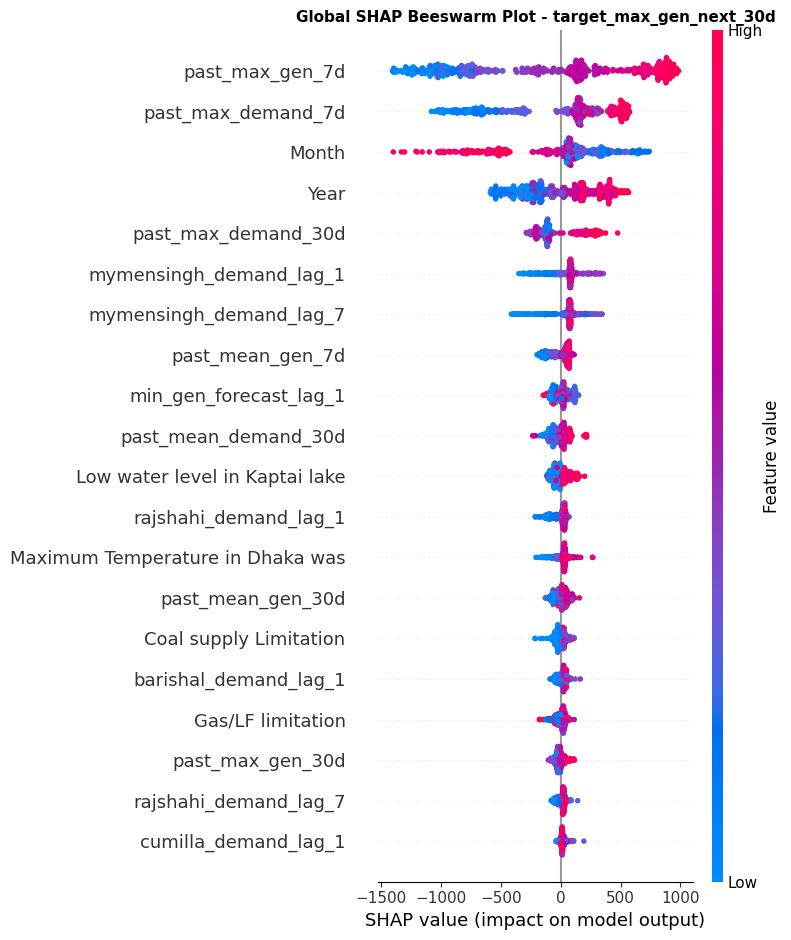

In [ ]:
import shap
import matplotlib.pyplot as plt

# 1. Target select (30-day generation: index 5)
target_idx = 5
target_name = TARGET[target_idx] if 'TARGET' in locals() else 'target_max_gen_next_30d'

# Extract the specific base estimator
single_target_model = best_tuned_xgb.estimators_[target_idx]

# 2. Initialize TreeExplainer and calculate SHAP values
explainer = shap.TreeExplainer(single_target_model)
shap_values = explainer(X_test_scaled)

# Get feature names from original X_test
feature_names = X_test.columns.tolist() if hasattr(X_test, "columns") else None

# 3. Create a clean single figure without extra blank space
fig, ax = plt.subplots(figsize=(10, 7))

# Plot Beeswarm with more features (max_display=20) and compact layout
shap.summary_plot(
    shap_values,
    X_test_scaled,
    plot_type="dot",
    feature_names=feature_names,
    max_display=20,
    show=False
)

plt.title(f"Global SHAP Beeswarm Plot - {target_name}", fontsize=11, fontweight='bold')
plt.tight_layout()
plt.show()

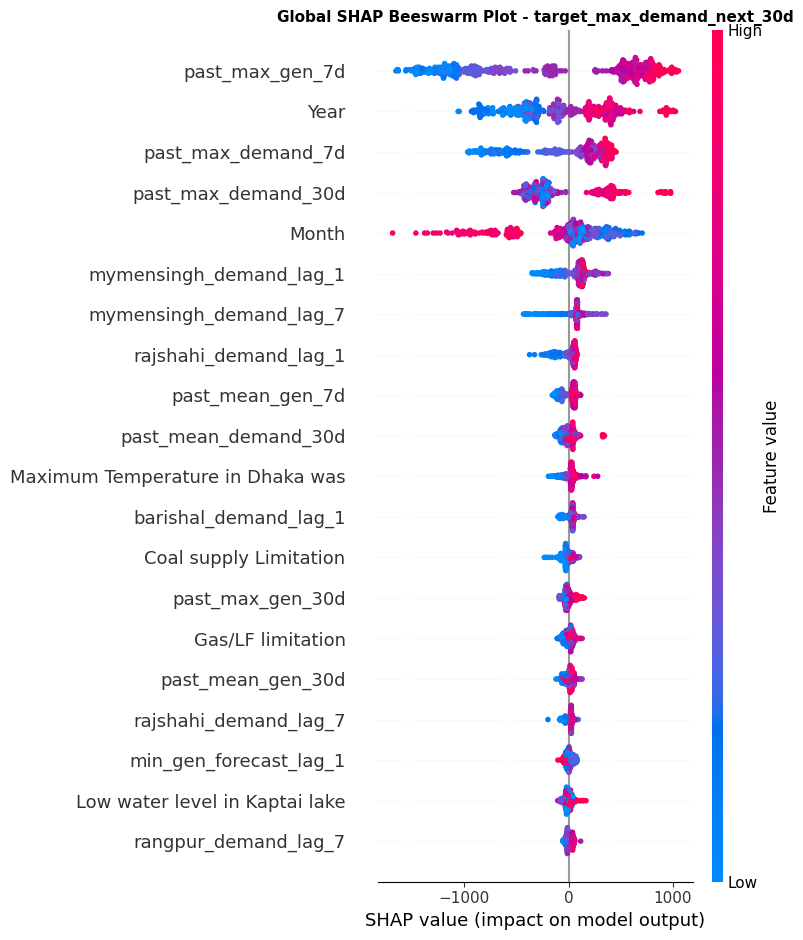

In [ ]:
import shap
import matplotlib.pyplot as plt

# 1. Target select (30-day deamnd: index 4)
target_idx = 4
target_name = TARGET[target_idx] if 'TARGET' in locals() else 'target_max_demand_next_30d'

# Extract the specific base estimator
single_target_model = best_tuned_xgb.estimators_[target_idx]

# 2. Initialize TreeExplainer and calculate SHAP values
explainer = shap.TreeExplainer(single_target_model)
shap_values = explainer(X_test_scaled)

# Get feature names from original X_test
feature_names = X_test.columns.tolist() if hasattr(X_test, "columns") else None

# 3. Create a clean single figure without extra blank space
fig, ax = plt.subplots(figsize=(10, 7))

# Plot Beeswarm with more features (max_display=20) and compact layout
shap.summary_plot(
    shap_values,
    X_test_scaled,
    plot_type="dot",
    feature_names=feature_names,
    max_display=20,
    show=False
)

plt.title(f"Global SHAP Beeswarm Plot - {target_name}", fontsize=11, fontweight='bold')
plt.tight_layout()
plt.show()

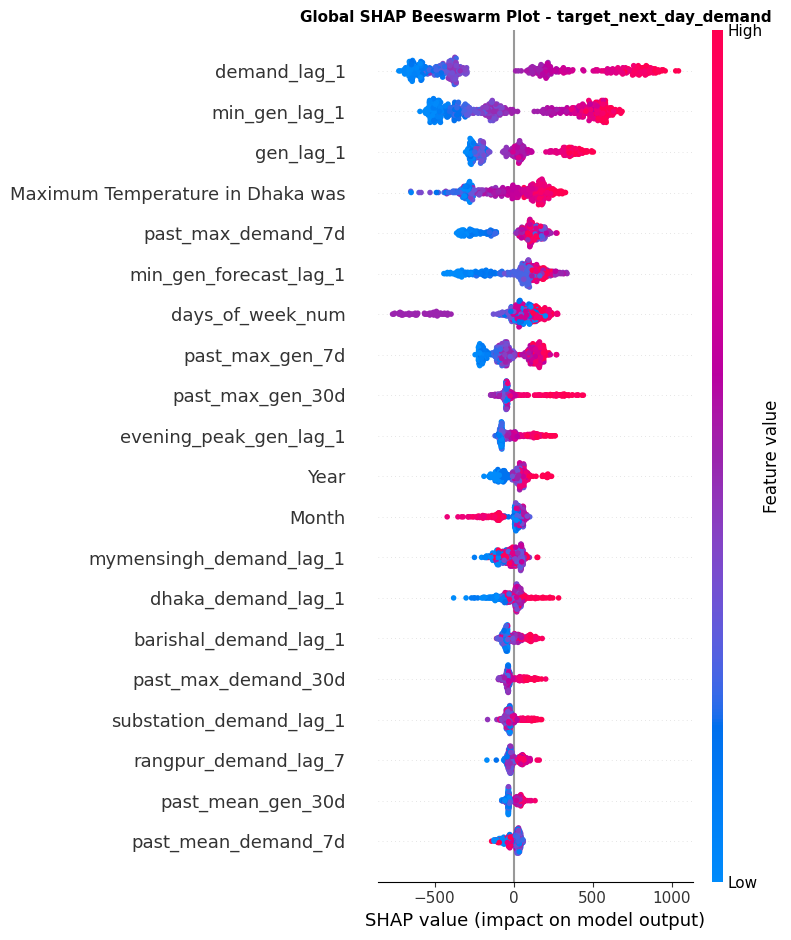

In [ ]:
## Nex_day Demand

import shap
import matplotlib.pyplot as plt

# 1. Next day demand-er jonno target_idx = 0 (ba apnar TARGET list onujayi demand-er index)
target_idx = 0
target_name = TARGET[target_idx] if 'TARGET' in locals() else 'target_next_day_demand'

# Extract the specific base estimator for this target
single_target_model = best_tuned_xgb.estimators_[target_idx]

# 2. Initialize TreeExplainer and calculate SHAP values
explainer = shap.TreeExplainer(single_target_model)
shap_values = explainer(X_test_scaled)

# Get feature names from original X_test
feature_names = X_test.columns.tolist() if hasattr(X_test, "columns") else None

# 3. Create a clean single figure for Next Day Demand
fig, ax = plt.subplots(figsize=(10, 7))

# Plot Beeswarm with max_display=20 for comprehensive feature view
shap.summary_plot(
    shap_values,
    X_test_scaled,
    plot_type="dot",
    feature_names=feature_names,
    max_display=20,
    show=False
)

plt.title(f"Global SHAP Beeswarm Plot - {target_name}", fontsize=11, fontweight='bold')
plt.tight_layout()
plt.show()

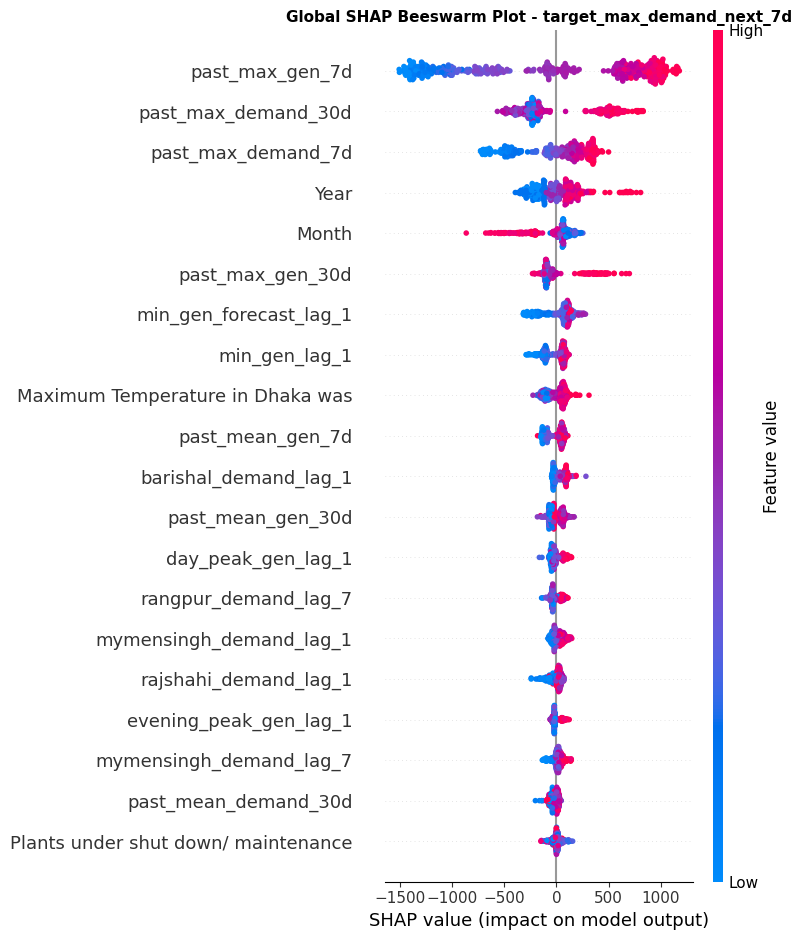

In [ ]:
import shap
import matplotlib.pyplot as plt

# 1. Target select (7-day generation: index 3)
target_idx = 2
target_name = TARGET[target_idx] if 'TARGET' in locals() else 'target_max_demand_next_7d'

# Extract the specific base estimator
single_target_model = best_tuned_xgb.estimators_[target_idx]

# 2. Initialize TreeExplainer and calculate SHAP values
explainer = shap.TreeExplainer(single_target_model)
shap_values = explainer(X_test_scaled)

# Get feature names from original X_test
feature_names = X_test.columns.tolist() if hasattr(X_test, "columns") else None

# 3. Create a clean single figure without extra blank space
fig, ax = plt.subplots(figsize=(10, 7))

# Plot Beeswarm with more features (max_display=20) and compact layout
shap.summary_plot(
    shap_values,
    X_test_scaled,
    plot_type="dot",
    feature_names=feature_names,
    max_display=20,
    show=False
)

plt.title(f"Global SHAP Beeswarm Plot - {target_name}", fontsize=11, fontweight='bold')
plt.tight_layout()
plt.show()

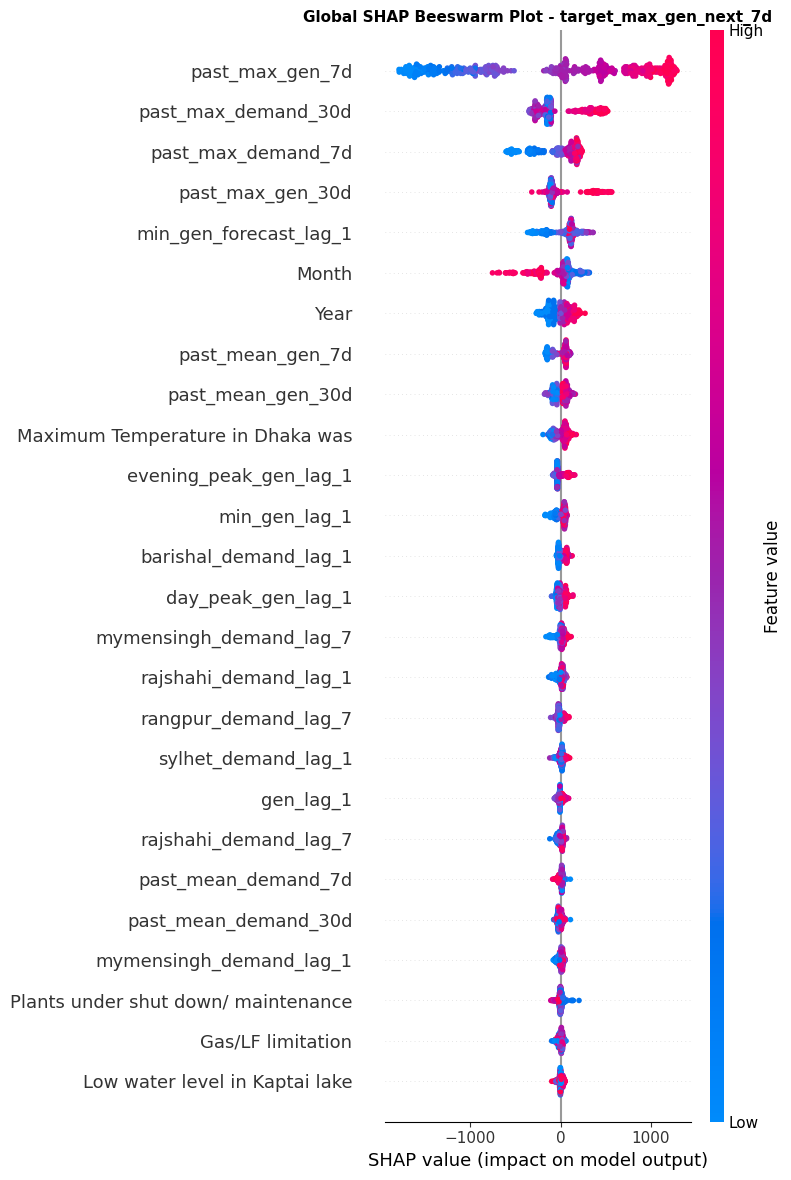

In [ ]:
import shap
import matplotlib.pyplot as plt

# 1. Target select (7-day generation: index 3)
target_idx = 3
target_name = TARGET[target_idx] if 'TARGET' in locals() else 'target_max_gen_next_7d'

# Extract the specific base estimator
single_target_model = best_tuned_xgb.estimators_[target_idx]

# 2. Initialize TreeExplainer and calculate SHAP values
explainer = shap.TreeExplainer(single_target_model)
shap_values = explainer(X_test_scaled)

# Get feature names from original X_test
feature_names = X_test.columns.tolist() if hasattr(X_test, "columns") else None

# 3. Create a clean single figure without extra blank space
fig, ax = plt.subplots(figsize=(10, 7))

# Plot Beeswarm with more features (max_display=20) and compact layout
shap.summary_plot(
    shap_values,
    X_test_scaled,
    plot_type="dot",
    feature_names=feature_names,
    max_display=26,
    show=False
)

plt.title(f"Global SHAP Beeswarm Plot - {target_name}", fontsize=11, fontweight='bold')
plt.tight_layout()
plt.show()

## Local SHAP Analysis

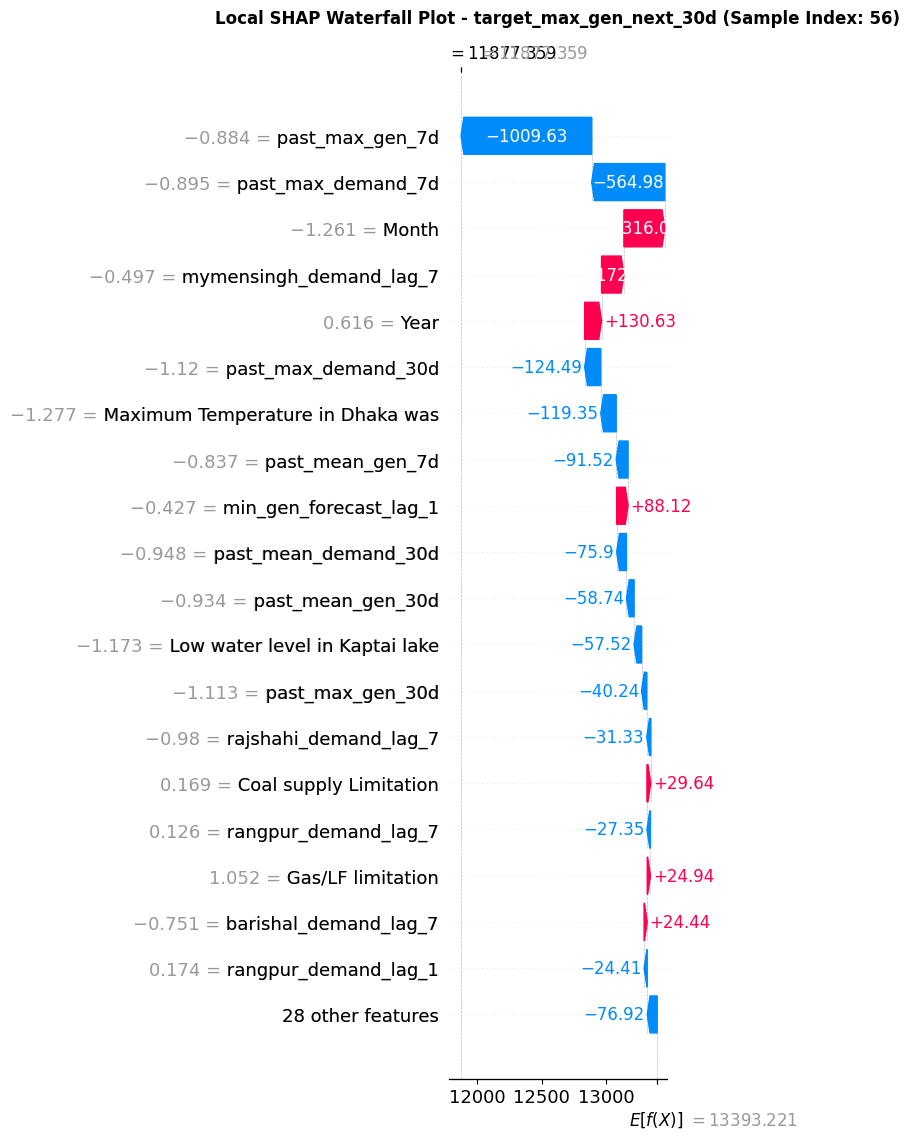

In [ ]:
import shap
import matplotlib.pyplot as plt

# 1. 30-day generation-er jonno target_idx = 5
target_idx = 5
target_name = TARGET[target_idx] if 'TARGET' in locals() else 'target_max_gen_next_30d'

# Extract base estimator
single_target_model = best_tuned_xgb.estimators_[target_idx]

# 2. Initialize TreeExplainer and calculate SHAP values
explainer = shap.TreeExplainer(single_target_model)
shap_values = explainer(X_test_scaled)

# 3. Explicitly assign feature names to the shap_values object
if hasattr(X_test, "columns"):
    shap_values.feature_names = X_test.columns.tolist()

# 4. Sample position
sample_pos = 56

# 5. Plot Local SHAP Waterfall Plot with title and max_display=20
plt.figure(figsize=(10, 8))
shap.plots.waterfall(shap_values[sample_pos], max_display=20, show=False)
plt.title(f"Local SHAP Waterfall Plot - {target_name} (Sample Index: {sample_pos})", fontsize=12, fontweight='bold', pad=15)
plt.tight_layout()
plt.show()

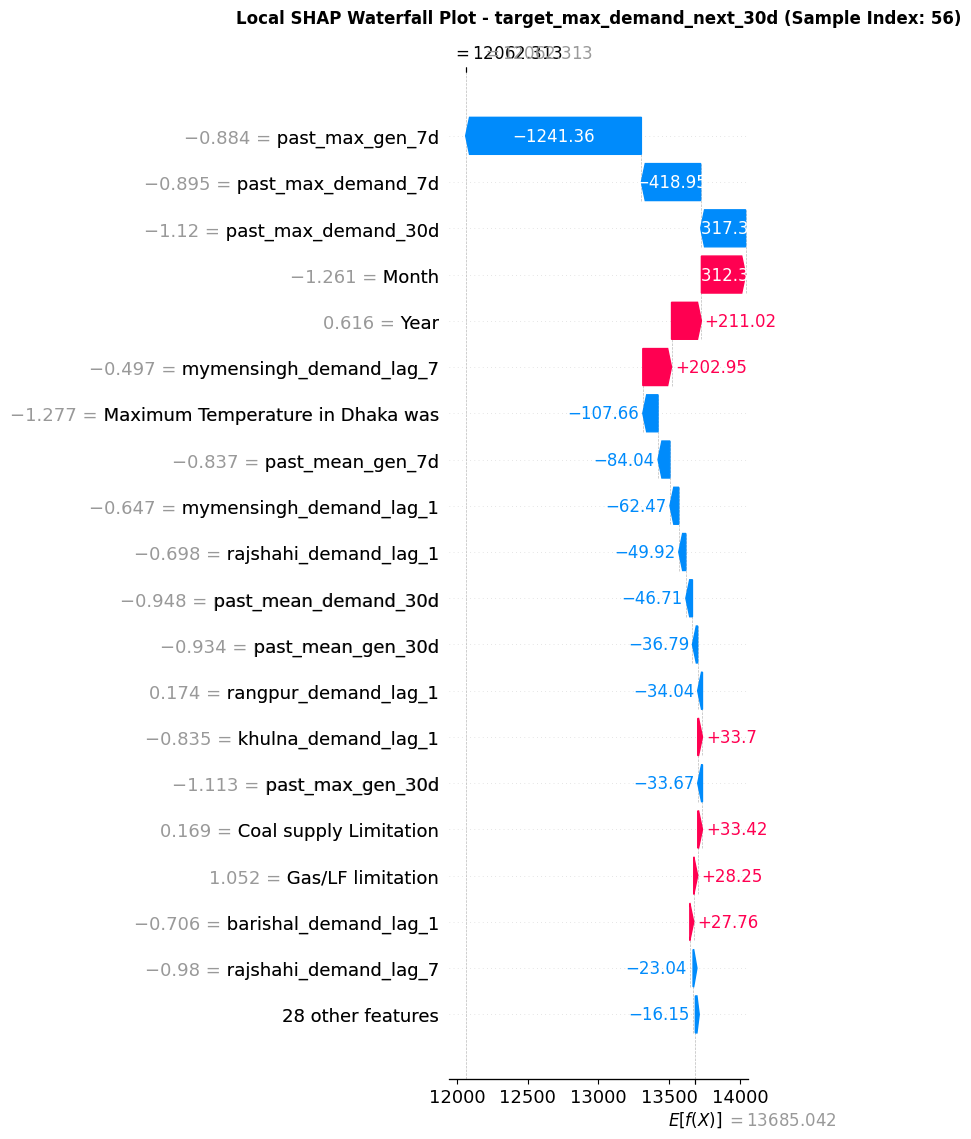

In [ ]:
import shap
import matplotlib.pyplot as plt

# 1. 30-day demand-er jonno target_idx = 5
target_idx = 4
target_name = TARGET[target_idx] if 'TARGET' in locals() else 'target_max_demand_next_30d'

# Extract base estimator
single_target_model = best_tuned_xgb.estimators_[target_idx]

# 2. Initialize TreeExplainer and calculate SHAP values
explainer = shap.TreeExplainer(single_target_model)
shap_values = explainer(X_test_scaled)

# 3. Explicitly assign feature names to the shap_values object
if hasattr(X_test, "columns"):
    shap_values.feature_names = X_test.columns.tolist()

# 4. Sample position
sample_pos = 56

# 5. Plot Local SHAP Waterfall Plot with title and max_display=20
plt.figure(figsize=(10, 8))
shap.plots.waterfall(shap_values[sample_pos], max_display=20, show=False)
plt.title(f"Local SHAP Waterfall Plot - {target_name} (Sample Index: {sample_pos})", fontsize=12, fontweight='bold', pad=15)
plt.tight_layout()
plt.show()

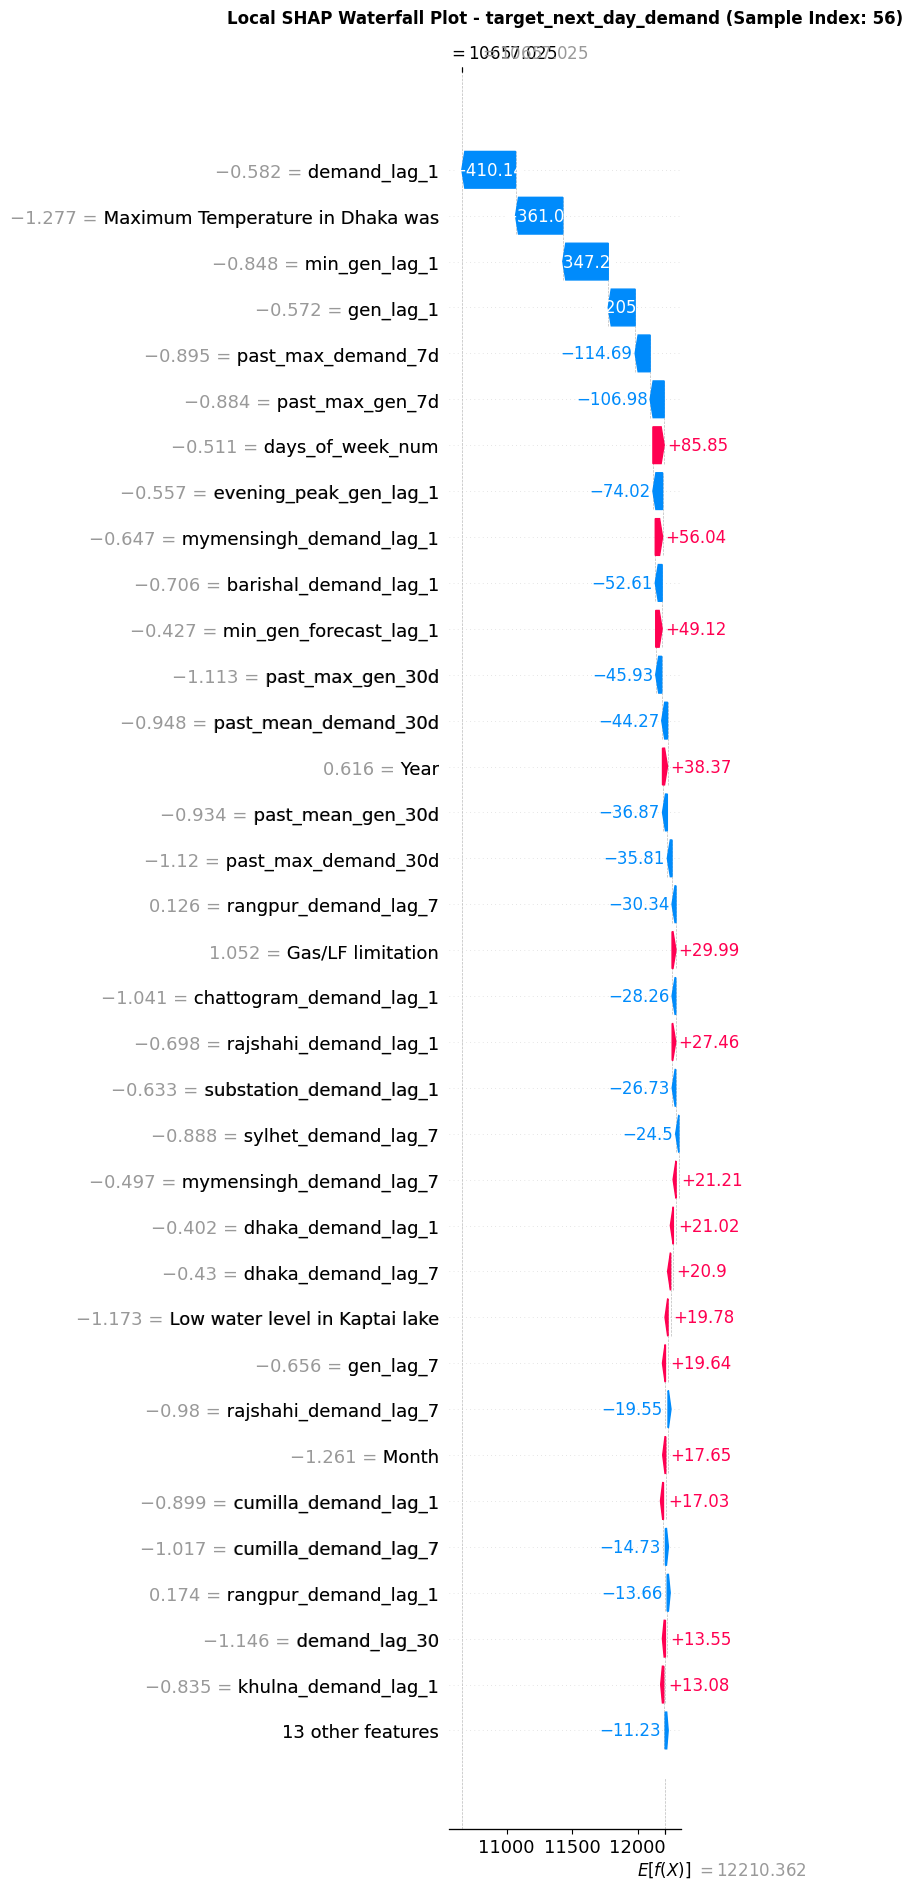

In [ ]:
import shap
import matplotlib.pyplot as plt

# 1. next-day demand-er jonno target_idx = 0
target_idx = 0
target_name = TARGET[target_idx] if 'TARGET' in locals() else 'target_next_day_demand'

# Extract base estimator
single_target_model = best_tuned_xgb.estimators_[target_idx]

# 2. Initialize TreeExplainer and calculate SHAP values
explainer = shap.TreeExplainer(single_target_model)
shap_values = explainer(X_test_scaled)

# 3. Explicitly assign feature names to the shap_values object
if hasattr(X_test, "columns"):
    shap_values.feature_names = X_test.columns.tolist()

# 4. Sample position
sample_pos = 56

# 5. Plot Local SHAP Waterfall Plot with title and max_display=20
plt.figure(figsize=(12, 10))
shap.plots.waterfall(shap_values[sample_pos], max_display=35, show=False)
plt.title(f"Local SHAP Waterfall Plot - {target_name} (Sample Index: {sample_pos})", fontsize=12, fontweight='bold', pad=15)
plt.tight_layout()
plt.show()

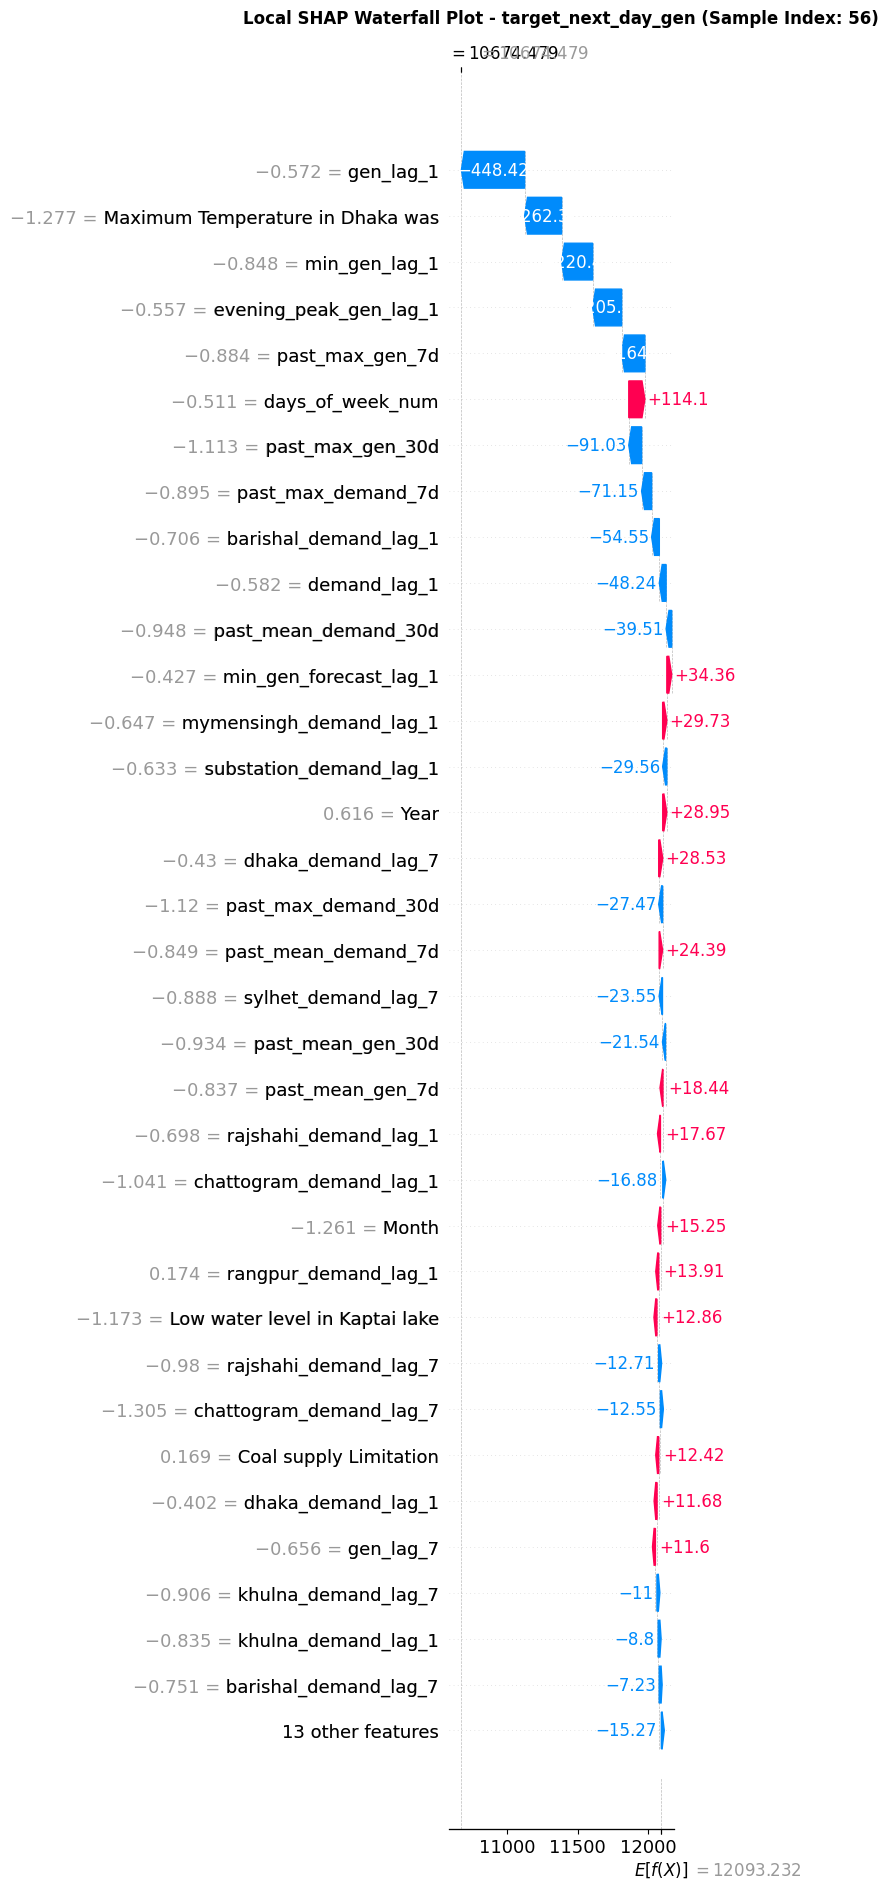

In [ ]:
import shap
import matplotlib.pyplot as plt

# 1. next-day generation- target_idx = 1
target_idx = 1
target_name = TARGET[target_idx] if 'TARGET' in locals() else 'target_next_day_gen'

# Extract base estimator
single_target_model = best_tuned_xgb.estimators_[target_idx]

# 2. Initialize TreeExplainer and calculate SHAP values
explainer = shap.TreeExplainer(single_target_model)
shap_values = explainer(X_test_scaled)

# 3. Explicitly assign feature names to the shap_values object
if hasattr(X_test, "columns"):
    shap_values.feature_names = X_test.columns.tolist()

# 4. Sample position
sample_pos = 56

# 5. Plot Local SHAP Waterfall Plot with title and max_display=20
plt.figure(figsize=(12, 10))
shap.plots.waterfall(shap_values[sample_pos], max_display=35, show=False)
plt.title(f"Local SHAP Waterfall Plot - {target_name} (Sample Index: {sample_pos})", fontsize=12, fontweight='bold', pad=15)
plt.tight_layout()
plt.show()

## Partial Dependence Plots (PDP) & ICE Plots

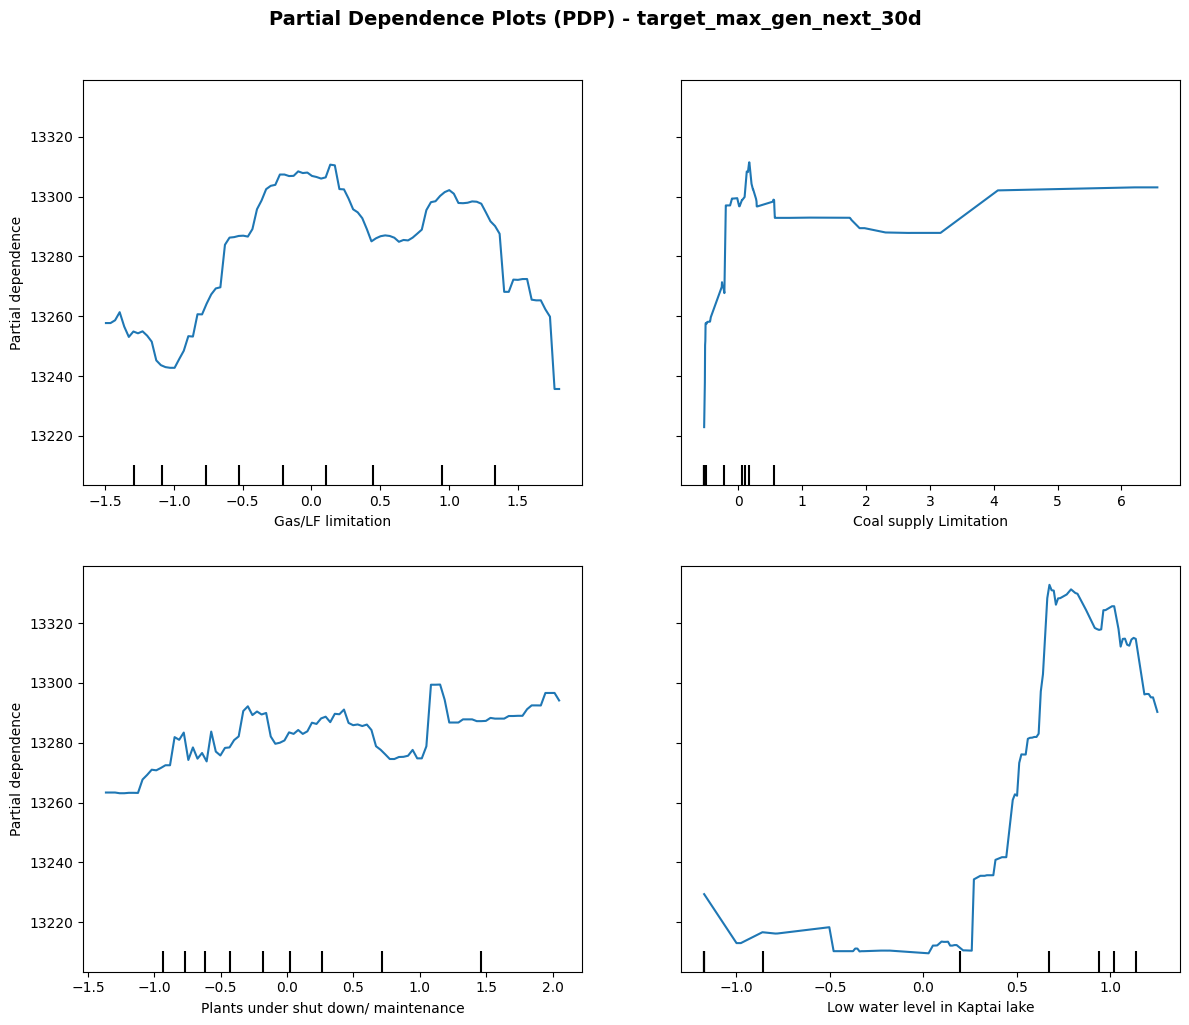

In [ ]:
import matplotlib.pyplot as plt
from sklearn.inspection import PartialDependenceDisplay

# 1. 30-day generation-er jonno target_idx = 5
target_idx = 5
target_name = TARGET[target_idx] if 'TARGET' in locals() else 'target_max_gen_next_30d'

# Extract the specific base estimator for this target
single_target_model = best_tuned_xgb.estimators_[target_idx]


features_to_plot = [
    'Maximum Temperature in Dhaka',
    'Gas/LF limitation',
    'Coal supply Limitation',
    'Plants under shut down/ maintenance',
    'Low water level in Kaptai lake'
]

# Check whether Feature in gulo dataframe
valid_features = [f for f in features_to_plot if f in X_test.columns]

if not valid_features:
    # if not exist then find by index diye or substring
    print("Warning: Some exact feature names didn't match. Please check X_test.columns names.")
    valid_features = X_test.columns[:5] # Fallback to first 5 if needed

# 3. Plotting PDP for those features
fig, ax = plt.subplots(figsize=(12, 10))
display = PartialDependenceDisplay.from_estimator(
    estimator=single_target_model,
    X=X_test_scaled,          # Scaled test data
    features=valid_features,    # Selected features list
    feature_names=X_test.columns.tolist() if hasattr(X_test, "columns") else None,
    kind='average',             # 'average' for PDP, 'both' or 'individual' for ICE lines
    n_cols=2,                   # Protita row-e 2 ta kore plot thakbe
    ax=ax
)

plt.suptitle(f"Partial Dependence Plots (PDP) - {target_name}", fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

## 17. Key Takeaways

1. **Bagging** (Random Forest, Extra Trees): strong and simple baselines
2. **Boosting** (XGBoost, LightGBM, CatBoost): usually the best single models on tabular data
3. **Stacking**: combines different models; often a small extra gain, but slower

**Evaluation:**
- **Accuracy** alone is not enough – also check precision, recall and F1
- **Macro average** treats all classes equally; **weighted average** follows class size
- **Confusion matrix** shows *which* classes are confused
- **ROC-AUC** measures how well the model separates the classes (1.0 = perfect)

**Important parameters:**
- **n_estimators / iterations:** number of trees
- **learning_rate:** step size of boosting
- **max_depth / depth:** tree complexity

---

## 19. Homework Assignment

### 📝 Task: Superstore Profitability Prediction

**Dataset:** Superstore Sales

**Kaggle Link:** https://www.kaggle.com/datasets/himanshuuike/superstore-sales-dataset

**File:** `samplesuperstore.csv` (upload to `MyDrive/datasets/`)

**Target:** create `profit_class` from the profit margin (= Profit / Sales):

| Class | Rule |
|---|---|
| 0 – Loss | Profit < 0 |
| 1 – Low margin | margin < 0.25 |
| 2 – High margin | margin ≥ 0.25 |

---

### Tasks:

**Task 1: Load & Explore Data**
- Load the dataset from Google Drive
- Display first rows, `info()`, `describe()`

**Task 2: Clean Data**
- Create the `profit_class` target
- Keep features: Ship Mode, Segment, Region, Category, Sub-Category, Sales, Quantity, Discount
- Drop the `Profit` column

**Task 3: Preprocess**
- Encode text columns with `LabelEncoder`
- Stratified train/test split (80/20, `random_state=20`)

**Task 4: Train Models**
- Random Forest, Extra Trees, XGBoost, LightGBM, CatBoost, Stacking

**Task 5: Evaluate**
- Comparison table: accuracy, precision, recall, F1 (macro and weighted), ROC-AUC
- Classification report for every model

**Task 6: Visualize**
- Confusion matrix for every model
- ROC curve (one-vs-rest) + AUC for every model


---



### Homework Starter Code:

Use the cells below to complete your homework.

In [ ]:
# TASK 1: Load and Explore Data
from google.colab import drive
drive.mount('/content/drive')

df = pd.read_csv('/content/drive/MyDrive/datasets/samplesuperstore.csv')
df.head()

# TODO: info(), describe(), correlation heatmap

In [ ]:
# TASK 2: Clean Data

# TODO: Create profit_class (0 = Loss, 1 = Low margin, 2 = High margin)
TARGET = "profit_class"
class_names = ["Loss", "Low margin", "High margin"]

margin = df["Profit"] / df["Sales"]
df[TARGET] = np.select([df["Profit"] < 0, margin < 0.25], [0, 1], default=2)

features = ["Ship Mode", "Segment", "Region", "Category", "Sub-Category",
            "Sales", "Quantity", "Discount"]
df = df[features + [TARGET]].drop_duplicates()
df.head()
# TODO: Keep the selected features + target
# TODO: Drop Profit

In [ ]:
# TASK 3: Preprocess

# TODO: Encode text columns
# TODO: Split data

In [ ]:
# TASK 4: Train Models

# TODO: Random Forest
# TODO: Extra Trees
# TODO: XGBoost
# TODO: LightGBM
# TODO: CatBoost
# TODO: Stacking

In [ ]:
# TASK 5: Evaluate

# TODO: Comparison table
# TODO: Classification reports

In [ ]:
# TASK 6: Visualize

# TODO: Confusion matrices
# TODO: ROC curves + AUC